# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Aarav Desai (aarav.desai@epfl.ch)
- Firstname Lastname (email@example.com)
- Nathan Kabas Kuroiwa (nathan.kabaskuroiwa@epfl.ch)

---

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [1]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


c:\Users\huawei\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Project dir: c:\Users\huawei\Desktop\EPFL\Quantitative Financial Risk Management\Project\QRM_Project_GitHub


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [2]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

(3393, 3) 2013-01-02 to 2026-06-30


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [3]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.012703,-0.008248,-0.002017
2013-01-04,-0.028250,0.035029,0.017569
2013-01-07,-0.005900,0.022689,0.001101
2013-01-08,0.002688,-0.012312,0.001980
2013-01-09,-0.015752,0.051311,-0.000660


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

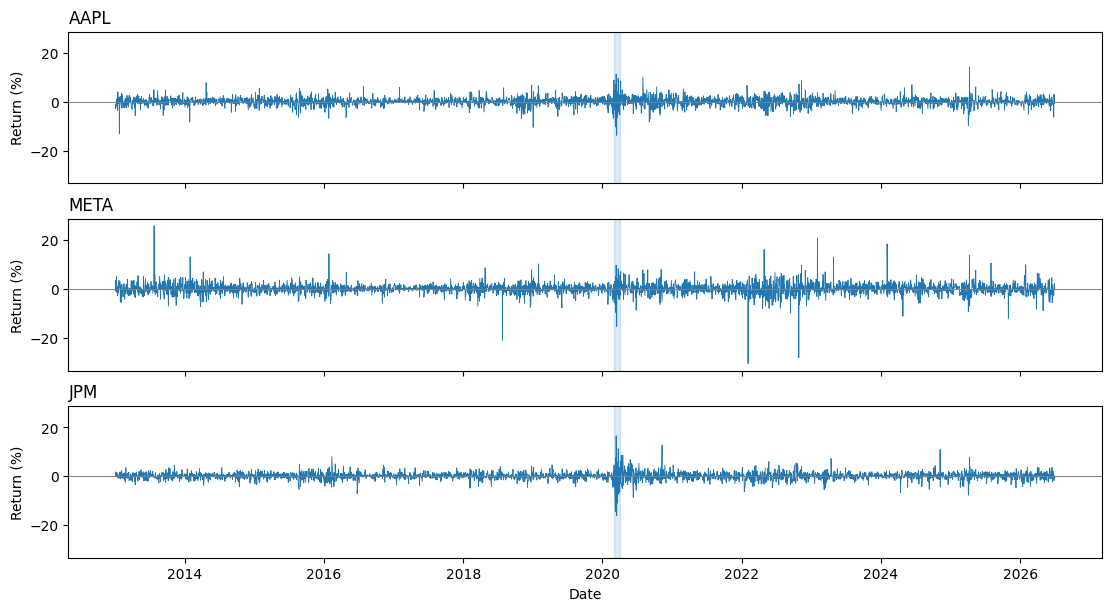

Largest abosulte returns for AAPL


,AAPL,META,JPM
Date,,,
2025-04-09,14.0,14.0,8.0
2020-03-16,-14.0,-15.0,-16.0
2013-01-24,-13.0,1.0,0.0


Largest abosulte returns for META


,AAPL,META,JPM
Date,,,
2022-02-03,-2.0,-31.0,-1.0
2022-10-27,-3.0,-28.0,0.0
2013-07-25,-0.0,26.0,-0.0


Largest abosulte returns for JPM


,AAPL,META,JPM
Date,,,
2020-03-13,11.0,10.0,17.0
2020-03-16,-14.0,-15.0,-16.0
2020-03-09,-8.0,-7.0,-15.0


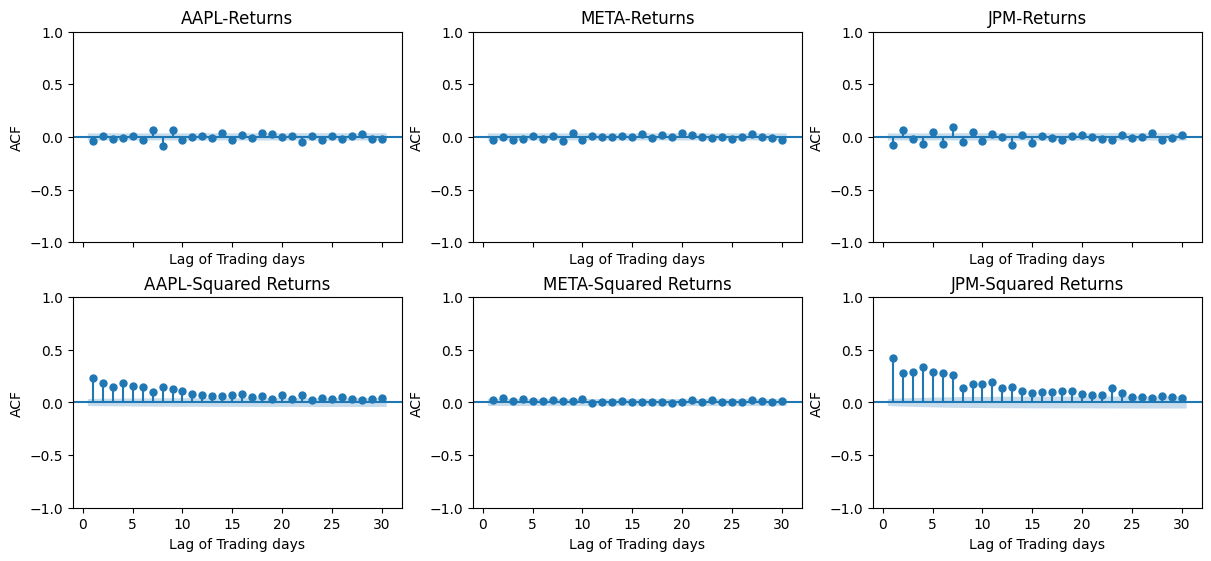

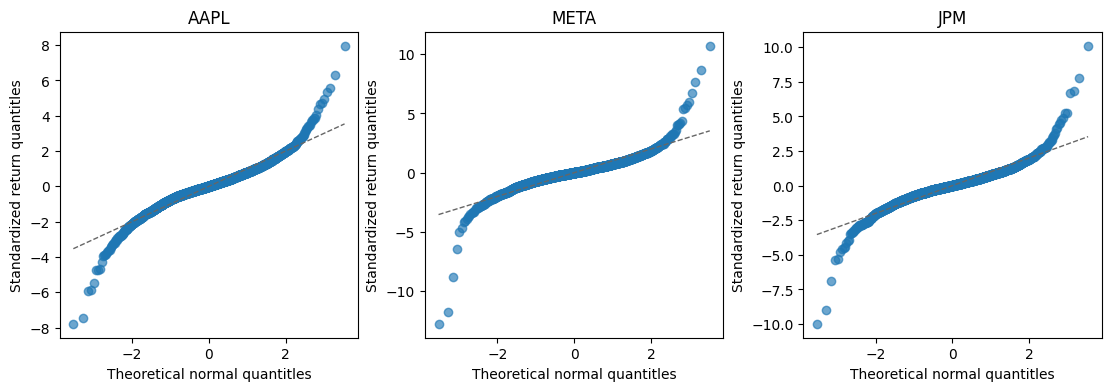

Stock,AAPL,META,JPM
Skewness,-0.225,-0.497,-0.0843
Kurtosis,9.81,27.4,15.9
JB statistic,6.59e+03,8.42e+04,2.37e+04
p_value,0,0,0


In [4]:
# Question 1
# (a)
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
fig,axes=plt.subplots(
    len(TICKERS),1, figsize=(11,6),
    sharex=True,sharey=True,layout="constrained"
)
for ax,ticker in zip(axes,TICKERS):
    ax.plot(returns.index,100*returns[ticker],linewidth=0.6)
    ax.axhline(0,color="0.5",linewidth=0.7)
    ax.axvspan(
        pd.Timestamp("2020-03-01"),
        pd.Timestamp("2020-04-01"),
        color="tab:blue",
        alpha=0.15,
    )
    ax.set_title(ticker,loc="left")
    ax.set_ylabel("Return (%)")
axes[-1].set_xlabel("Date")
fig.savefig(OUT_DIR/"q1a_returns.jpg",bbox_inches="tight")
plt.show()
for ticker in TICKERS:
    dates=returns[ticker].abs().nlargest(3).index
    print(f"Largest abosulte returns for {ticker}")
    display(100*returns.loc[dates,TICKERS].round(2))
# (b)
fig,axes=plt.subplots(
    2,len(TICKERS),figsize=(12,5.5),
    sharex=True,layout="constrained"
)
lb_rows=[]
for col,ticker in enumerate(TICKERS):
    r=returns[ticker]
    for row, (label,series) in enumerate([
        ("Returns",r),
        ("Squared Returns",r**2)
    ]):
        ax=axes[row,col]
        plot_acf(series,lags=30,zero=False,ax=ax)
        ax.set_title(f"{ticker}-{label}")
        ax.set_xlabel("Lag of Trading days")
        ax.set_ylabel("ACF")
        result=acorr_ljungbox(
            series,lags=[LB_LAGS],model_df=0,return_df=True
        ).loc[LB_LAGS]
        lb_rows.append({
            "Stock":ticker,
            "Series":label,
            "LB statistic":result["lb_stat"],
            "p_value":result["lb_pvalue"]
        })
fig.savefig(OUT_DIR/"q1b_acf.jpg",bbox_inches="tight")
plt.show()
lb_table=pd.DataFrame(lb_rows).pivot(
    index="Series",columns="Stock",values=["LB statistic","p_value"]
)
lb_table=lb_table.swaplevel(0,1,axis=1).reindex(
    columns=pd.MultiIndex.from_product(
        [TICKERS,["LB statistic","p_value"]],names=["Stock",None]
    )
)
display(lb_table.style.format("{:.3g}"))
# (c)
fig,axes=plt.subplots(
    1,len(TICKERS),figsize=(11,3.8),layout="constrained"
)
jb_rows=[]
for ax,ticker in zip(axes,TICKERS):
    r=returns[ticker]
    standardized=(r-r.mean())/r.std(ddof=1)
    normal_q,sample_q=stats.probplot(
        standardized,dist="norm",fit=False
    )
    ax.scatter(normal_q,sample_q,alpha=0.65)
    ax.plot(normal_q,normal_q,color="0.4",linestyle="--",linewidth=1)
    ax.set_title(ticker)
    ax.set_xlabel("Theoretical normal quantitles")
    ax.set_ylabel("Standardized return quantitles")
    jb=stats.jarque_bera(r)
    jb_rows.append({
        "Stock":ticker,
        "Skewness":stats.skew(r),
        "Kurtosis":stats.kurtosis(r,fisher=False),
        "JB statistic":jb.statistic,
        "p_value":jb.pvalue
    })
fig.savefig(OUT_DIR/"q1c_normal_qq.jpg",bbox_inches="tight")
plt.show()
jb_table=pd.DataFrame(jb_rows).set_index("Stock").T
display(jb_table.style.format("{:.3g}"))

## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

Estimated Window:2013-01-03 00:00:00to 2015-01-02 00:00:00
Number of losses per stock:504


Stock,AAPL,META,JPM
Degrees of freedom,4.132,4.679,6.483
Location (%),-0.106,-0.131,-0.096
Scale (%),1.113,1.780,0.974


One-day VaR and ES (% log-loss)


VaR ranking from lowest to highest


Stock,AAPL,META,JPM
Alpha,,,
0.975,Historical < Student-t < Gaussian,Historical < Student-t < Gaussian,Gaussian < Student-t < Historical
0.990,Gaussian < Historical < Student-t,Historical < Gaussian < Student-t,Gaussian < Historical < Student-t


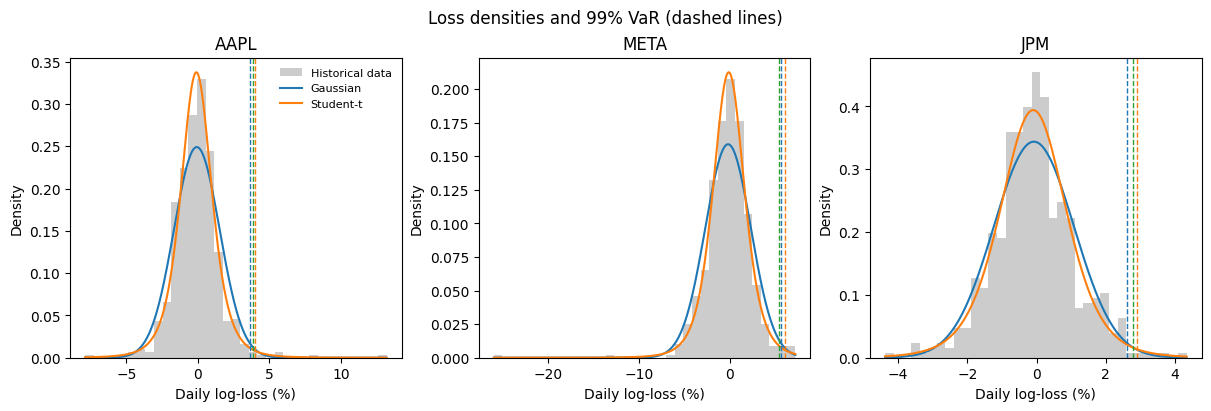

In [5]:
# Question 2
window_loss = losses.iloc[:WINDOW]          # one column per stock
#(a) historical method
assert len(window_loss)==WINDOW
print(f"Estimated Window:{window_loss.index[0]}" f"to {window_loss.index[-1]}")
print(f"Number of losses per stock:{len(window_loss)}")
q2_rows=[]
def historical_var_es(x,alpha):
    ordered=np.sort(np.asarray(x))[::-1] # -1 reverse the ascending order
    tail_count=len(ordered)*(1-alpha)
    k=int(np.floor(tail_count))
    var=ordered[k]
    es=(ordered[:k].sum()+(tail_count-k)*var)/tail_count
    return var, es
for ticker in TICKERS:
    for alpha in ALPHAS:
        var,es=historical_var_es(window_loss[ticker],alpha)
        q2_rows.append({
            "Stock":ticker,
            "Method":"Historical",
            "Alpha":alpha,
            "VaR":var,
            "ES":es
        })
#(b) Gaussian method
normal_fits={}
def gaussian_var_es(mu,sigma,alpha):
    z=stats.norm.ppf(alpha) # ppf = Percent Point Function [Inverse of CDF]
    var=mu+sigma*z
    es=mu+sigma*stats.norm.pdf(z)/(1-alpha)
    return var,es
for ticker in TICKERS:
    x=window_loss[ticker]
    mu=x.mean()
    sigma=x.std(ddof=0)
    normal_fits[ticker]=(mu,sigma)
    for alpha in ALPHAS:
        var,es=gaussian_var_es(mu,sigma,alpha)
        q2_rows.append({
            "Stock":ticker,
            "Method":"Gaussian",
            "Alpha":alpha,
            "VaR":var,
            "ES":es
        })
#(c) Student t-distribution method
t_fits = {}
fit_rows = []

def fit_student_t(x):
    x_pct = 100 * np.asarray(x, dtype=float)
    candidates = []

    for start_nu in [2, 3, 5, 10, 30, 100]:
        nu, loc_pct, scale_pct = stats.t.fit(
            x_pct,
            start_nu,
            loc=np.median(x_pct),
            scale=np.std(x_pct),
        )

        if nu > 0 and scale_pct > 0:
            loglik = stats.t.logpdf(
                x_pct, nu, loc=loc_pct, scale=scale_pct
            ).sum()
            if np.isfinite(loglik):
                candidates.append((loglik, nu, loc_pct, scale_pct))

    if not candidates:
        raise RuntimeError("No valid Student-t fit was found.")

    _, nu, loc_pct, scale_pct = max(candidates, key=lambda fit: fit[0])
    return nu, loc_pct / 100, scale_pct / 100


def student_t_var_es(nu, loc, scale, alpha):
    q = stats.t.ppf(alpha, nu)
    var = loc + scale * q

    if nu <= 1:
        return var, np.inf

    tail_mean = (
        stats.t.pdf(q, nu) / (1 - alpha)
        * (nu + q**2) / (nu - 1)
    )
    return var, loc + scale * tail_mean


for ticker in TICKERS:
    nu, loc, scale = fit_student_t(window_loss[ticker])
    t_fits[ticker] = (nu, loc, scale)

    fit_rows.append({
        "Stock": ticker,
        "Degrees of freedom": nu,
        "Location (%)": 100 * loc,
        "Scale (%)": 100 * scale,
    })

    for alpha in ALPHAS:
        var, es = student_t_var_es(nu, loc, scale, alpha)
        q2_rows.append({
            "Stock": ticker,
            "Method": "Student-t",
            "Alpha": alpha,
            "VaR": var,
            "ES": es,
        })

t_fit_table = pd.DataFrame(fit_rows).set_index("Stock").T
display(t_fit_table.style.format("{:.3f}"))
#(d) Fitted densities and VaR
methods = ["Historical", "Gaussian", "Student-t"]
q2_results = pd.DataFrame(q2_rows)

q2_pct = q2_results.assign(
    VaR=lambda df: 100 * df["VaR"],
    ES=lambda df: 100 * df["ES"],
)

q2_table = q2_pct.pivot(
    index=["Alpha", "Method"], columns="Stock", values=["VaR", "ES"]
)
q2_table = q2_table.swaplevel(0, 1, axis=1).reindex(
    index=pd.MultiIndex.from_product(
        [ALPHAS, methods], names=["Alpha", "Method"]
    ),
    columns=pd.MultiIndex.from_product(
        [TICKERS, ["VaR", "ES"]], names=["Stock", "Risk measure"]
    ),
)

print("One-day VaR and ES (% log-loss)")
display(q2_table.style.format("{:.3f}"))

rankings = (
    q2_results.sort_values("VaR")
    .groupby(["Alpha", "Stock"])["Method"]
    .agg(" < ".join)
    .unstack("Stock")
    .reindex(columns=TICKERS)
)

print("VaR ranking from lowest to highest")
display(rankings)

colors = {
    "Historical": "tab:green",
    "Gaussian": "tab:blue",
    "Student-t": "tab:orange",
}

fig, axes = plt.subplots(
    1, len(TICKERS), figsize=(12, 4), layout="constrained"
)

for ax, ticker in zip(axes, TICKERS):
    x_pct = 100 * window_loss[ticker]
    mu, sigma = normal_fits[ticker]
    nu, loc, scale = t_fits[ticker]

    tail_var = q2_pct.loc[
        (q2_pct["Stock"] == ticker) & (q2_pct["Alpha"] == 0.99)
    ]
    right = max(x_pct.max(), tail_var["VaR"].max())
    grid = np.linspace(x_pct.min(), right, 600)

    ax.hist(x_pct, bins=35, density=True, color="0.8", label="Historical data")
    ax.plot(
        grid, stats.norm.pdf(grid, loc=100 * mu, scale=100 * sigma),
        color=colors["Gaussian"], label="Gaussian"
    )
    ax.plot(
        grid, stats.t.pdf(grid, nu, loc=100 * loc, scale=100 * scale),
        color=colors["Student-t"], label="Student-t"
    )

    for row in tail_var.itertuples(index=False):
        ax.axvline(
            row.VaR, color=colors[row.Method], linestyle="--", linewidth=1
        )

    ax.set_title(ticker)
    ax.set_xlabel("Daily log-loss (%)")
    ax.set_ylabel("Density")

axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Loss densities and 99% VaR (dashed lines)")
fig.savefig(OUT_DIR / "q2d_fitted_densities.jpg", bbox_inches="tight")
plt.show()

## Question 3 -- Backtesting

Forecast every day of the evaluation period `losses.iloc[EVAL_START:]`, each model estimated on the
`WINDOW` days before the forecast day. Historical simulation, Gaussian and Student-$t$ are recomputed
every day. Write the Kupiec, Christoffersen, Acerbi-Szekely, Fissler-Ziegel, pinball-loss and
Diebold-Mariano functions yourself, from the course slides (Kupiec, Christoffersen) and Appendix A of
the project statement (the others); they are
reused unchanged in Questions 4 and 5.

The combined VaR backtest table collects the VaR backtests of Questions 3-5: append one row per
stock, method and level to `backtest_rows` as you go. The ES backtest table ($\alpha=0.975$) collects
the Acerbi-Szekely and Fissler-Ziegel results of Questions 3 and 4 in `es_rows`.

In [6]:
# Question 3
eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ

# ----------------------------------------------------------------------
# Backtesting and Scoring Functions (Kupiec, Christoffersen, Pinball, Acerbi-Szekely, Fissler-Ziegel)
# ----------------------------------------------------------------------

def kupiec_uc(hits: np.ndarray, alpha: float) -> tuple[float, float]:
    """Kupiec Unconditional Coverage test (LR_uc) and p-value."""
    hits = np.asarray(hits, dtype=int)
    N = len(hits)
    x = int(np.sum(hits))
    p = 1.0 - alpha
    p_hat = x / N

    if x == 0:
        lr_uc = -2.0 * N * np.log(1.0 - p)
    elif x == N:
        lr_uc = -2.0 * N * np.log(p)
    else:
        lr_uc = 2.0 * (x * np.log(p_hat / p) + (N - x) * np.log((1.0 - p_hat) / (1.0 - p)))
    lr_uc = max(0.0, float(lr_uc))
    p_val = float(stats.chi2.sf(lr_uc, df=1))
    return lr_uc, p_val


def christoffersen_ind(hits: np.ndarray) -> tuple[float, float]:
    """Christoffersen Independence test (LR_ind) and p-value."""
    hits = np.asarray(hits, dtype=int)
    N = len(hits)
    i_prev = hits[:-1]
    i_curr = hits[1:]

    T00 = int(np.sum((i_prev == 0) & (i_curr == 0)))
    T01 = int(np.sum((i_prev == 0) & (i_curr == 1)))
    T10 = int(np.sum((i_prev == 1) & (i_curr == 0)))
    T11 = int(np.sum((i_prev == 1) & (i_curr == 1)))

    pi_0 = T01 / (T00 + T01) if (T00 + T01) > 0 else 0.0
    pi_1 = T11 / (T10 + T11) if (T10 + T11) > 0 else 0.0
    pi = (T01 + T11) / (N - 1) if (N - 1) > 0 else 0.0

    ll_null = 0.0
    if 0 < pi < 1:
        ll_null = (T00 + T10) * np.log(1.0 - pi) + (T01 + T11) * np.log(pi)

    ll_alt = 0.0
    if 0 < pi_0 < 1:
        ll_alt += T00 * np.log(1.0 - pi_0) + T01 * np.log(pi_0)
    if 0 < pi_1 < 1:
        ll_alt += T10 * np.log(1.0 - pi_1) + T11 * np.log(pi_1)

    lr_ind = 2.0 * (ll_alt - ll_null)
    lr_ind = max(0.0, float(lr_ind))
    p_val = float(stats.chi2.sf(lr_ind, df=1))
    return lr_ind, p_val


def christoffersen_cc(hits: np.ndarray, alpha: float) -> tuple[float, float]:
    """Christoffersen Conditional Coverage test (LR_cc = LR_uc + LR_ind) and p-value."""
    lr_uc, _ = kupiec_uc(hits, alpha)
    lr_ind, _ = christoffersen_ind(hits)
    lr_cc = lr_uc + lr_ind
    p_val = float(stats.chi2.sf(lr_cc, df=2))
    return lr_cc, p_val


def pinball_loss_bp(loss: np.ndarray, var: np.ndarray, alpha: float) -> float:
    """Mean pinball (tick) loss in basis points (1 bp = 10^-4)."""
    diff = np.asarray(loss) - np.asarray(var)
    rho = np.where(diff >= 0, alpha * diff, (1.0 - alpha) * (-diff))
    return float(np.mean(rho) * 10_000.0)


def acerbi_szekely_stat(loss: np.ndarray, var: np.ndarray, es: np.ndarray, alpha: float) -> float:
    """Acerbi-Szekely Z_2 test statistic."""
    p = 1.0 - alpha
    N = len(loss)
    hits = (loss > var)
    Z = np.sum((loss * hits) / (p * es)) / N - 1.0
    return float(Z)


def simulate_acerbi_szekely_pval(
    var: np.ndarray,
    es: np.ndarray,
    mu: np.ndarray,
    sig: np.ndarray,
    alpha: float,
    dist: str,
    nu: np.ndarray = None,
    z_obs: float = 0.0,
    m_sim: int = M_SIM,
    seed: int = SEED,
) -> float:
    """Simulate p-value for Acerbi-Szekely test under H0."""
    local_rng = np.random.default_rng(seed)
    N = len(var)
    p = 1.0 - alpha
    chunk_size = 2000
    z_sim = []

    for _ in range(m_sim // chunk_size):
        if dist == "normal":
            eps = local_rng.standard_normal((chunk_size, N))
        elif dist == "t":
            raw_t = local_rng.standard_t(df=nu, size=(chunk_size, N))
            scale_fac = np.sqrt((nu - 2.0) / nu)
            eps = raw_t * scale_fac
        else:
            raise ValueError(f"Unknown dist: {dist}")

        L_sim = -mu + sig * (-eps)
        hits_sim = (L_sim > var)
        z_chunk = np.sum((L_sim * hits_sim) / (p * es), axis=1) / N - 1.0
        z_sim.append(z_chunk)

    z_sim = np.concatenate(z_sim)
    p_val = float(np.mean(z_sim >= z_obs))
    return p_val


def fissler_ziegel_scores(loss: np.ndarray, var: np.ndarray, es: np.ndarray, alpha: float) -> np.ndarray:
    """Daily 0-homogeneous Fissler-Ziegel joint score of Appendix A.3 (Patton et al., 2019), for positive losses
    and es > 0; lower is better. Note the + sign of the exception term: with a - sign the score is not consistent."""
    p = 1.0 - alpha
    I = (loss > var).astype(float)
    return (1.0 / (p * es)) * I * (loss - var) + (var / es) + np.log(es) - 1.0


def fissler_ziegel_loss(loss: np.ndarray, var: np.ndarray, es: np.ndarray, alpha: float) -> float:
    """0-homogeneous Fissler-Ziegel strictly consistent joint loss for (VaR, ES), averaged over the forecast days."""
    return float(np.mean(fissler_ziegel_scores(loss, var, es, alpha)))


### Question 3 -- rolling forecasts of the three Question 2 methods

Every forecast day $t$ of the evaluation period (2,888 days from 5 January 2015) each method is re-estimated
on the $W=504$ losses $L_{t-504},\dots,L_{t-1}$, so the forecast for day $t$ uses data up to $t-1$ only.

* **HS**: $\widehat{\mathrm{VaR}}_\alpha=L_{k+1,W}$ and the interpolated $\widehat{\mathrm{ES}}_\alpha$ of Question 2(a), $k=\lfloor W(1-\alpha)\rfloor$.
* **Gaussian**: sample mean and standard deviation (variance denominator $W$, as in Question 2); $\widehat{\mathrm{VaR}}_\alpha=\hat\mu+\hat\sigma\Phi^{-1}(\alpha)$, $\widehat{\mathrm{ES}}_\alpha=\hat\mu+\hat\sigma\,\varphi(\Phi^{-1}(\alpha))/(1-\alpha)$.
* **Student-$t$**: $(\nu,\mu,\sigma)$ by maximum likelihood, $\sigma$ the scale (not the standard deviation); with $q=t_\nu^{-1}(\alpha)$,
  $\widehat{\mathrm{VaR}}_\alpha=\hat\mu+\hat\sigma q$ and $\widehat{\mathrm{ES}}_\alpha=\hat\mu+\hat\sigma\,\frac{g_\nu(q)}{1-\alpha}\,\frac{\nu+q^2}{\nu-1}$.
  Because `scipy.stats.t.fit` can stop at a local optimum (project statement, Question 2(c)), the likelihood is
  maximised with L-BFGS-B (analytic gradient, data centred by the median and scaled by the MAD), started at
  $\nu=5$ and at the previous day's estimate, keeping the better optimum.

In [7]:
# Question 3: rolling one-day-ahead VaR/ES forecasts of the three methods of Question 2
import statsmodels.api as sm
from numpy.lib.stride_tricks import sliding_window_view
from scipy.optimize import minimize
from scipy.special import gammaln, digamma

Q3_METHODS = ["HS", "Gaussian", "Student-t"]
NU_BOUNDS = (1.01, 1000.0)          # nu > 1 keeps the t ES finite; fits that end on a bound are counted below
eval_dates = eval_loss.index
N_eval = len(eval_dates)


def hs_var_es(windows: np.ndarray, alpha: float) -> tuple[np.ndarray, np.ndarray]:
    """Historical simulation VaR/ES of Question 2(a), one estimation window per row."""
    W = windows.shape[1]
    w_tail = W * (1.0 - alpha)                          # W(1 - alpha)
    k = int(np.floor(w_tail + 1e-9))
    srt = -np.sort(-windows, axis=1)                    # L_{1,W} >= L_{2,W} >= ... >= L_{W,W}
    var = srt[:, k]                                     # L_{k+1,W}
    es = (srt[:, :k].sum(axis=1) + (w_tail - k) * srt[:, k]) / w_tail
    return var, es


def gaussian_var_es(mu, sigma, alpha: float):
    """Gaussian VaR/ES of the loss, (mu, sigma) the sample mean and standard deviation (denominator W) of the window."""
    q = stats.norm.ppf(alpha)
    return mu + sigma * q, mu + sigma * stats.norm.pdf(q) / (1.0 - alpha)


def student_t_var_es(nu, mu, sigma, alpha: float):
    """Location-scale Student-t VaR/ES of the loss (sigma is the scale parameter, not the standard deviation)."""
    q = stats.t.ppf(alpha, nu)
    return mu + sigma * q, mu + sigma * stats.t.pdf(q, nu) / (1.0 - alpha) * (nu + q**2) / (nu - 1.0)


def _t_negloglik(theta: np.ndarray, z: np.ndarray) -> tuple[float, np.ndarray]:
    """Negative log-likelihood of t(nu, mu, exp(log_sigma)) on z and its analytic gradient."""
    nu, mu, log_sig = theta
    sig = np.exp(log_sig)
    r = (z - mu) / sig
    r2 = r * r
    n = z.size
    log_a = np.log1p(r2 / nu)
    loglik = n * (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(nu * np.pi) - log_sig) - 0.5 * (nu + 1) * log_a.sum()
    w = (nu + 1) / (nu + r2)
    g_nu = 0.5 * n * (digamma((nu + 1) / 2) - digamma(nu / 2) - 1 / nu) - 0.5 * log_a.sum() + 0.5 * (nu + 1) * np.sum(r2 / (nu * (nu + r2)))
    g_mu = np.sum(w * r) / sig
    g_log_sig = -n + np.sum(w * r2)
    return -loglik, -np.array([g_nu, g_mu, g_log_sig])


def fit_student_t(x: np.ndarray, warm=None) -> tuple[float, float, float, bool]:
    """ML estimate (nu, mu, sigma) of a location-scale t, plus a convergence flag.
    The data are centred by the median and scaled by the MAD so the problem is well conditioned; L-BFGS-B is
    started from nu=5 and, if given, from the previous day's estimate `warm`, and the better optimum is kept."""
    med = np.median(x)
    s = 1.4826 * np.median(np.abs(x - med))
    z = (x - med) / s
    starts = [np.array([5.0, 0.0, 0.0])]
    if warm is not None:
        starts.append(np.array([np.clip(warm[0], *NU_BOUNDS), (warm[1] - med) / s, np.log(warm[2] / s)]))
    best = None
    for theta0 in starts:
        res = minimize(_t_negloglik, theta0, args=(z,), jac=True, method="L-BFGS-B",
                       bounds=[NU_BOUNDS, (-10.0, 10.0), (-10.0, 5.0)])
        if best is None or res.fun < best.fun:
            best = res
    nu, mu_z, log_sig_z = best.x
    return float(nu), float(med + s * mu_z), float(s * np.exp(log_sig_z)), bool(best.success)


q3_var, q3_es = {}, {}       # (stock, method, alpha) -> pd.Series of forecasts on the evaluation days
q3_params = {}               # (stock, method) -> pd.DataFrame of the daily parameter estimates
q3_windows = {}              # stock -> (N_eval, WINDOW) array; row i is the window of forecast day i (HS draws in 3(c))
tfit_rows = []

for ticker in TICKERS:
    L_all = losses[ticker].to_numpy()
    win = sliding_window_view(L_all, WINDOW)[EVAL_START - WINDOW : len(L_all) - WINDOW]   # row i: L_{t_i-W}, ..., L_{t_i-1}
    assert win.shape == (N_eval, WINDOW) and np.array_equal(win[-1], L_all[-WINDOW - 1 : -1])
    q3_windows[ticker] = win

    # Gaussian: sample moments of each window, variance denominator W as in Question 2
    mu_g, sd_g = win.mean(axis=1), win.std(axis=1, ddof=0)
    q3_params[(ticker, "Gaussian")] = pd.DataFrame({"mu": mu_g, "sigma": sd_g}, index=eval_dates)

    # Student-t: maximum likelihood on each window, warm-started from the previous day's estimate
    est = np.empty((N_eval, 3))
    converged = np.empty(N_eval, dtype=bool)
    warm = None
    for i in range(N_eval):
        nu_i, mu_i, sig_i, converged[i] = fit_student_t(win[i], warm)
        est[i] = warm = (nu_i, mu_i, sig_i)
    nu_t, mu_t, sig_t = est.T
    q3_params[(ticker, "Student-t")] = pd.DataFrame({"nu": nu_t, "mu": mu_t, "sigma": sig_t}, index=eval_dates)
    on_bound = np.isclose(nu_t, NU_BOUNDS[0]) | np.isclose(nu_t, NU_BOUNDS[1])
    tfit_rows.append({"stock": ticker, "fits": N_eval, "not converged": int((~converged).sum()),
                      "on a nu bound": int(on_bound.sum())})

    for alpha in ALPHAS:
        forecasts_t = {"HS": hs_var_es(win, alpha),
                       "Gaussian": gaussian_var_es(mu_g, sd_g, alpha),
                       "Student-t": student_t_var_es(nu_t, mu_t, sig_t, alpha)}
        for method, (v, e) in forecasts_t.items():
            q3_var[(ticker, method, alpha)] = pd.Series(v, index=eval_dates)
            q3_es[(ticker, method, alpha)] = pd.Series(e, index=eval_dates)

print(f"{N_eval} forecast days per stock, {eval_dates[0].date()} to {eval_dates[-1].date()}")
print("Rolling Student-t fits (convergence and parameter-space boundary):")
display(pd.DataFrame(tfit_rows).set_index("stock"))

2888 forecast days per stock, 2015-01-05 to 2026-06-30
Rolling Student-t fits (convergence and parameter-space boundary):


,fits,not converged,on a nu bound
stock,,,
AAPL,2888,0,0
META,2888,0,0
JPM,2888,0,0


In [8]:
# Question 3(a): VaR backtests of the three methods -> rows of the combined VaR tables
def var_backtest_row(stock: str, method: str, alpha: float, loss: np.ndarray, var: np.ndarray) -> dict:
    """One row of the combined VaR table: exceptions, Kupiec, Christoffersen and average pinball loss."""
    hits = loss > var
    return {"stock": stock, "method": method, "alpha": alpha, "x": int(hits.sum()), "expected": round(len(loss) * (1.0 - alpha), 2),
            "hit": float(hits.mean()), "p_uc": kupiec_uc(hits, alpha)[1], "p_ind": christoffersen_ind(hits)[1],
            "p_cc": christoffersen_cc(hits, alpha)[1], "pinball_bp": pinball_loss_bp(loss, var, alpha)}


def fmt_p(p: float) -> str:
    return f"{p:.3f}" if p >= 1e-3 else f"{p:.0e}"


def formatted(df: pd.DataFrame, fmt: dict) -> pd.DataFrame:
    """Copy of df with the listed columns turned into display strings (no jinja2/Styler dependency)."""
    out = df.copy()
    for col, f in fmt.items():
        out[col] = out[col].map(f if callable(f) else f.format)
    return out


def var_table(rows: list, alpha: float, methods: list | None = None) -> pd.DataFrame:
    """Combined VaR backtest table at one level alpha: one row per stock and method."""
    df = pd.DataFrame(rows)
    df = df[df["alpha"] == alpha]
    if methods is not None:
        df = df[df["method"].isin(methods)]
    df = df.sort_values("stock", key=lambda s: s.map(TICKERS.index), kind="stable")
    return (df.set_index(["stock", "method"])[["x", "expected", "hit", "p_uc", "p_ind", "p_cc", "pinball_bp"]]
              .rename(columns={"x": "exceptions", "hit": "hit rate", "p_uc": "Kupiec p", "p_ind": "Ind. p",
                               "p_cc": "CC p", "pinball_bp": "pinball (bp)"}))


VAR_TABLE_FMT = {"expected": "{:.1f}", "hit rate": "{:.2%}", "Kupiec p": fmt_p, "Ind. p": fmt_p, "CC p": fmt_p,
                 "pinball (bp)": "{:.2f}"}

backtest_rows[:] = [r for r in backtest_rows if r["method"] not in Q3_METHODS]   # makes the cell safe to re-run
for ticker in TICKERS:
    loss_t = eval_loss[ticker].to_numpy()
    for method in Q3_METHODS:
        for alpha in ALPHAS:
            backtest_rows.append(var_backtest_row(ticker, method, alpha, loss_t, q3_var[(ticker, method, alpha)].to_numpy()))

for alpha in ALPHAS:
    tab = var_table(backtest_rows, alpha, Q3_METHODS)
    tab.to_csv(OUT_DIR / f"q3_var_backtest_{alpha}.csv")
    print(f"VaR backtest, alpha = {alpha} (Question 3 rows)")
    display(formatted(tab, VAR_TABLE_FMT))

VaR backtest, alpha = 0.975 (Question 3 rows)


exceptions expected hit rate Kupiec p Ind. p   CC p  \
stock method                                                           
AAPL  HS                 86     72.2    2.98%    0.110  0.004  0.005   
      Gaussian          105     72.2    3.64%    2e-04  4e-04  2e-06   
      Student-t         103     72.2    3.57%    6e-04  6e-05  8e-07   
META  HS                 75     72.2    2.60%    0.740  0.016  0.051   
      Gaussian           78     72.2    2.70%    0.495  2e-04  9e-04   
      Student-t          89     72.2    3.08%    0.053  4e-04  3e-04   
JPM   HS                 83     72.2    2.87%    0.208  4e-08  1e-07   
      Gaussian           96     72.2    3.32%    0.007  1e-05  2e-06   
      Student-t          92     72.2    3.19%    0.023  6e-07  3e-07   

                pinball (bp)  
stock method                  
AAPL  HS               13.60  
      Gaussian         13.75  
      Student-t        13.72  
META  HS               18.26  
      Gaussian         18.32  
      Student-t        18.28  
JPM   HS               13.02  
      Gaussian         13.21  
      Student-t        13.30

VaR backtest, alpha = 0.99 (Question 3 rows)


exceptions expected hit rate Kupiec p Ind. p   CC p  \
stock method                                                           
AAPL  HS                 41     28.9    1.42%    0.033  0.138  0.034   
      Gaussian           63     28.9    2.18%    3e-08  0.014  1e-08   
      Student-t          41     28.9    1.42%    0.033  0.138  0.034   
META  HS                 40     28.9    1.39%    0.049  0.125  0.045   
      Gaussian           52     28.9    1.80%    1e-04  0.002  5e-06   
      Student-t          38     28.9    1.32%    0.104  0.102  0.070   
JPM   HS                 42     28.9    1.45%    0.022  1e-06  5e-07   
      Gaussian           64     28.9    2.22%    2e-08  7e-07  5e-13   
      Student-t          47     28.9    1.63%    0.002  6e-06  3e-07   

                pinball (bp)  
stock method                  
AAPL  HS                7.24  
      Gaussian          7.66  
      Student-t         7.21  
META  HS               10.37  
      Gaussian         10.68  
      Student-t        10.50  
JPM   HS                7.22  
      Gaussian          7.59  
      Student-t         7.35

In [9]:
# Question 3(b): which methods fail coverage / independence at the 5% level, and Kupiec vs conditional-coverage disagreements
TEST_LEVEL = 0.05
q3_bt = pd.DataFrame([r for r in backtest_rows if r["method"] in Q3_METHODS])
verdict = q3_bt[["alpha", "stock", "method", "x", "expected"]].copy()
verdict["coverage (Kupiec)"] = np.where(q3_bt["p_uc"] >= TEST_LEVEL, "pass",
                                        np.where(q3_bt["x"] > q3_bt["expected"], "FAIL (too many)", "FAIL (too few)"))
verdict["independence"] = np.where(q3_bt["p_ind"] < TEST_LEVEL, "FAIL", "pass")
verdict["cond. coverage"] = np.where(q3_bt["p_cc"] < TEST_LEVEL, "FAIL", "pass")
display(verdict.sort_values(["alpha", "stock"], key=lambda s: s.map(TICKERS.index) if s.name == "stock" else s, kind="stable")
               .set_index(["alpha", "stock", "method"]))

print("Kupiec and conditional-coverage verdicts disagree:")
for r in q3_bt.itertuples():
    uc_rej, cc_rej = r.p_uc < TEST_LEVEL, r.p_cc < TEST_LEVEL
    if uc_rej != cc_rej:
        cause = ("independence: the exceptions cluster, LR_ind pushes LR_cc over the chi2(2) critical value" if cc_rej else
                 "coverage: LR_uc alone is significant, but adding a small LR_ind and moving to 2 df dilutes it")
        print(f"  {r.stock:5s} {r.method:9s} alpha={r.alpha}: x={r.x} vs {r.expected:.1f}, p_uc={fmt_p(r.p_uc)}, "
              f"p_ind={fmt_p(r.p_ind)}, p_cc={fmt_p(r.p_cc)} -> {cause}")

x  expected coverage (Kupiec) independence  \
alpha stock method                                                    
0.975 AAPL  HS          86     72.20              pass         FAIL   
            Gaussian   105     72.20   FAIL (too many)         FAIL   
            Student-t  103     72.20   FAIL (too many)         FAIL   
      META  HS          75     72.20              pass         FAIL   
            Gaussian    78     72.20              pass         FAIL   
            Student-t   89     72.20              pass         FAIL   
      JPM   HS          83     72.20              pass         FAIL   
            Gaussian    96     72.20   FAIL (too many)         FAIL   
            Student-t   92     72.20   FAIL (too many)         FAIL   
0.990 AAPL  HS          41     28.88   FAIL (too many)         pass   
            Gaussian    63     28.88   FAIL (too many)         FAIL   
            Student-t   41     28.88   FAIL (too many)         pass   
      META  HS          40     28.88   FAIL (too many)         pass   
            Gaussian    52     28.88   FAIL (too many)         FAIL   
            Student-t   38     28.88              pass         pass   
      JPM   HS          42     28.88   FAIL (too many)         FAIL   
            Gaussian    64     28.88   FAIL (too many)         FAIL   
            Student-t   47     28.88   FAIL (too many)         FAIL   

                      cond. coverage  
alpha stock method                    
0.975 AAPL  HS                  FAIL  
            Gaussian            FAIL  
            Student-t           FAIL  
      META  HS                  pass  
            Gaussian            FAIL  
            Student-t           FAIL  
      JPM   HS                  FAIL  
            Gaussian            FAIL  
            Student-t           FAIL  
0.990 AAPL  HS                  FAIL  
            Gaussian            FAIL  
            Student-t           FAIL  
      META  HS                  FAIL  
            Gaussian            FAIL  
            Student-t           pass  
      JPM   HS                  FAIL  
            Gaussian            FAIL  
            Student-t           FAIL

Kupiec and conditional-coverage verdicts disagree:
  AAPL  HS        alpha=0.975: x=86 vs 72.2, p_uc=0.110, p_ind=0.004, p_cc=0.005 -> independence: the exceptions cluster, LR_ind pushes LR_cc over the chi2(2) critical value
  META  Gaussian  alpha=0.975: x=78 vs 72.2, p_uc=0.495, p_ind=2e-04, p_cc=9e-04 -> independence: the exceptions cluster, LR_ind pushes LR_cc over the chi2(2) critical value
  META  Student-t alpha=0.975: x=89 vs 72.2, p_uc=0.053, p_ind=4e-04, p_cc=3e-04 -> independence: the exceptions cluster, LR_ind pushes LR_cc over the chi2(2) critical value
  JPM   HS        alpha=0.975: x=83 vs 72.2, p_uc=0.208, p_ind=4e-08, p_cc=1e-07 -> independence: the exceptions cluster, LR_ind pushes LR_cc over the chi2(2) critical value


In [10]:
# Question 3(c): Acerbi-Szekely Z test of the ES forecasts at alpha = 0.975 with M = M_SIM simulated samples
ALPHA_ES = 0.975


def simulate_z_null(var: np.ndarray, es: np.ndarray, alpha: float, draw_losses, m_sim: int = M_SIM,
                    seed: int = SEED, chunk: int = 1000) -> np.ndarray:
    """Simulated null distribution of Z (Appendix A.2): the forecasts (var, es) are held fixed and
    draw_losses(rng, m) returns an (m, N) array whose column t is drawn from day t's forecast distribution."""
    local_rng = np.random.default_rng(seed)
    N = len(var)
    z = np.empty(m_sim)
    for s in range(0, m_sim, chunk):
        m = min(chunk, m_sim - s)
        L_sim = draw_losses(local_rng, m)
        z[s : s + m] = np.where(L_sim > var, L_sim, 0.0) @ (1.0 / es) / (N * (1.0 - alpha)) - 1.0
    return z


def q3_loss_sampler(ticker: str, method: str):
    """Draws from each day's forecast distribution: resampling the window (HS) or the fitted Gaussian / t.
    (simulate_acerbi_szekely_pval above is written for the GARCH models: it cannot resample a window, and its
    unit-variance t needs nu > 2, while the rolling t fit here has nu < 2 on some days.)"""
    days = np.arange(N_eval)
    if method == "HS":
        win = q3_windows[ticker]
        return lambda r, m: win[days, r.integers(0, WINDOW, size=(m, N_eval))]
    par = q3_params[(ticker, method)]
    mu, sig = par["mu"].to_numpy(), par["sigma"].to_numpy()
    if method == "Gaussian":
        return lambda r, m: mu + sig * r.standard_normal((m, N_eval))
    nu = par["nu"].to_numpy()
    return lambda r, m: mu + sig * r.standard_t(nu, size=(m, N_eval))


es_rows[:] = [r for r in es_rows if r["method"] not in Q3_METHODS]   # makes the cell safe to re-run
z_null_rows = []             # summary of each simulated null: shows why it depends on the method (last part of 3(c))
for ticker in TICKERS:
    loss_t = eval_loss[ticker].to_numpy()
    for method in Q3_METHODS:
        v = q3_var[(ticker, method, ALPHA_ES)].to_numpy()
        e = q3_es[(ticker, method, ALPHA_ES)].to_numpy()
        Z = acerbi_szekely_stat(loss_t, v, e, ALPHA_ES)
        z_null = simulate_z_null(v, e, ALPHA_ES, q3_loss_sampler(ticker, method))
        es_rows.append({"stock": ticker, "method": method, "Z": Z, "p_Z": float(np.mean(z_null >= Z)),
                        "FZ": fissler_ziegel_loss(loss_t, v, e, ALPHA_ES)})
        z_null_rows.append({"stock": ticker, "method": method, "null mean": z_null.mean(), "null sd": z_null.std(),
                            "null 95% quantile": np.quantile(z_null, 0.95)})

q3_es_table = (pd.DataFrame([r for r in es_rows if r["method"] in Q3_METHODS]).set_index(["stock", "method"])
                 .rename(columns={"p_Z": "p-value (Z)", "FZ": "avg FZ score"}))
q3_es_table.to_csv(OUT_DIR / "q3_es_backtest_0.975.csv")
print("ES backtest, alpha = 0.975 (Question 3 rows)")
display(formatted(q3_es_table, {"Z": "{:.3f}", "p-value (Z)": "{:.4f}", "avg FZ score": "{:.4f}"}))
print("Simulated null distribution of Z for each method:")
display(pd.DataFrame(z_null_rows).set_index(["stock", "method"]).round(4))

ES backtest, alpha = 0.975 (Question 3 rows)


Z p-value (Z) avg FZ score
stock method                                   
AAPL  HS         0.248      0.0115      -2.9104
      Gaussian   0.782      0.0000      -2.8332
      Student-t  0.372      0.0075      -2.8997
META  HS         0.125      0.1153      -2.6174
      Gaussian   0.496      0.0000      -2.5361
      Student-t  0.329      0.0113      -2.5956
JPM   HS         0.250      0.0124      -2.9591
      Gaussian   0.745      0.0000      -2.8617
      Student-t  0.351      0.0120      -2.9145

Simulated null distribution of Z for each method:


null mean  null sd  null 95% quantile
stock method                                          
AAPL  HS           -0.0337   0.1197             0.1683
      Gaussian      0.0013   0.1180             0.1979
      Student-t     0.0013   0.1333             0.2299
META  HS           -0.0329   0.1292             0.1828
      Gaussian      0.0013   0.1180             0.1980
      Student-t     0.0013   0.1324             0.2244
JPM   HS           -0.0324   0.1201             0.1687
      Gaussian      0.0013   0.1180             0.1978
      Student-t    -0.0005   0.1417             0.2354

In [11]:
# Question 3(d): Fissler-Ziegel ranking at alpha = 0.975 and Diebold-Mariano test of best vs second best
def diebold_mariano(score_a: np.ndarray, score_b: np.ndarray, nw_lags: int = NW_LAGS) -> tuple[float, float, float]:
    """DM test of H0: E[S_A - S_B] = 0 (Appendix A.3): OLS of d_t on a constant with a Newey-West standard error.
    Returns (mean difference, t-statistic, two-sided p-value). Reusable for the FZ and pinball comparisons of Q4-Q5."""
    d = np.asarray(score_a, dtype=float) - np.asarray(score_b, dtype=float)
    ols = sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": nw_lags})
    return float(d.mean()), float(ols.tvalues[0]), float(ols.pvalues[0])


q3_fz_daily = {}             # (stock, method) -> daily FZ scores at alpha = 0.975
dm_rows = []
for ticker in TICKERS:
    loss_t = eval_loss[ticker].to_numpy()
    for method in Q3_METHODS:
        q3_fz_daily[(ticker, method)] = fissler_ziegel_scores(
            loss_t, q3_var[(ticker, method, ALPHA_ES)].to_numpy(), q3_es[(ticker, method, ALPHA_ES)].to_numpy(), ALPHA_ES)
    ranked = sorted(Q3_METHODS, key=lambda m: q3_fz_daily[(ticker, m)].mean())
    best, second = ranked[0], ranked[1]
    d_bar, t_dm, p_dm = diebold_mariano(q3_fz_daily[(ticker, best)], q3_fz_daily[(ticker, second)])
    row = {"stock": ticker}
    for k, m in enumerate(ranked, 1):
        row[f"rank {k}"] = f"{m} ({q3_fz_daily[(ticker, m)].mean():.4f})"
    row.update({"DM: best - 2nd": d_bar, "DM t-stat": t_dm, "DM p-value": p_dm,
                "significant at 5%": "yes" if p_dm < 0.05 else "no"})
    dm_rows.append(row)

q3_dm_table = pd.DataFrame(dm_rows).set_index("stock")
q3_dm_table.to_csv(OUT_DIR / "q3_fz_ranking_dm.csv")
print("Average Fissler-Ziegel score at alpha = 0.975 (lower is better) and DM test best vs second best:")
display(formatted(q3_dm_table, {"DM: best - 2nd": "{:.4f}", "DM t-stat": "{:.2f}", "DM p-value": "{:.4f}"}))

Average Fissler-Ziegel score at alpha = 0.975 (lower is better) and DM test best vs second best:


,rank 1,rank 2,rank 3,DM: best - 2nd,DM t-stat,DM p-value,significant at 5%
stock,,,,,,,
AAPL,HS (-2.9104),Student-t (-2.8997),Gaussian (-2.8332),-0.0107,-1.01,0.3106,no
META,HS (-2.6174),Student-t (-2.5956),Gaussian (-2.5361),-0.0218,-1.36,0.1752,no
JPM,HS (-2.9591),Student-t (-2.9145),Gaussian (-2.8617),-0.0446,-2.59,0.0096,yes


## Question 4 -- AR-GARCH conditional VaR and ES

(a) Mean model, full sample: fit AR($p$), $p=0,\dots,3$, with constant variance on the same
observations, e.g. `ARX(y, lags=p, hold_back=3)` from `arch.univariate`; pick $p$ by BIC (also report
AIC); Ljung-Box on the residuals (`model_df=p`) and on their squares.
(b) Fit `arch_model(y, mean="AR", lags=p, vol="GARCH", p=1, q=1, dist=..., hold_back=3)` on the full
sample with `dist="normal"` and `dist="t"` (use `mean="Constant"` if $p=0$); Ljung-Box on the
standardized residuals of the Gaussian fit (`model_df=p`) and their squares (`model_df=2`).
(c) Re-estimate both inside the rolling scheme every `REFIT` days with the same $p$. Between refits,
keep the parameters fixed but advance $\hat\mu_t$ and $\hat\sigma_t$ daily with the realized
returns (for example with `arch_model(...).fix(params)` on the data up to the forecast day). Fit on
returns in percent (`100 * R`) to avoid `arch` convergence warnings, and convert the forecasts back.
(d) Backtest both and add them to the two tables.

In [12]:
# Question 4(a): Mean model, full sample AR(p) selection
from arch.univariate import ARX
from statsmodels.stats.diagnostic import acorr_ljungbox

print("=" * 80)
print("Question 4(a): AR(p) Mean Model on Full Sample")
print("=" * 80)

best_p = {}
ar_results = {}
ar_summary_rows = []

for ticker in TICKERS:
    # Fit on percent returns to avoid convergence issues
    y = 100 * returns[ticker]
    print(f"\n--- Stock: {ticker} ---")

    aic_list = []
    bic_list = []
    p_models = []

    for p in range(4):
        lags = list(range(1, p + 1)) if p > 0 else None
        # Hold back 3 observations so all models p=0..3 are estimated on the same sample
        mod = ARX(y, lags=lags, hold_back=3)
        res = mod.fit(disp="off")
        aic_list.append(res.aic)
        bic_list.append(res.bic)
        p_models.append(res)
        print(f"AR({p}): AIC = {res.aic:10.4f},  BIC = {res.bic:10.4f}")

    opt_p = int(np.argmin(bic_list))
    best_p[ticker] = opt_p
    opt_res = p_models[opt_p]
    ar_results[ticker] = opt_res
    print(f"--> Selected p by BIC for {ticker}: p = {opt_p}")

    # Ljung-Box test on residuals (model_df=p) and on squared residuals (model_df=0)
    resid = opt_res.resid.dropna()
    lb_resid = acorr_ljungbox(resid, lags=[LB_LAGS], model_df=opt_p)
    lb_sq = acorr_ljungbox(resid**2, lags=[LB_LAGS], model_df=0)

    stat_resid = lb_resid["lb_stat"].values[0]
    pval_resid = lb_resid["lb_pvalue"].values[0]
    stat_sq = lb_sq["lb_stat"].values[0]
    pval_sq = lb_sq["lb_pvalue"].values[0]

    print(f"Ljung-Box on residuals (model_df={opt_p}): Q({LB_LAGS}) = {stat_resid:.4f}, p-value = {pval_resid:.4e}")
    print(f"Ljung-Box on squared residuals:          Q({LB_LAGS}) = {stat_sq:.4f}, p-value = {pval_sq:.4e}")

    ar_summary_rows.append({
        "Stock": ticker,
        "Selected p (BIC)": opt_p,
        "AIC": aic_list[opt_p],
        "BIC": bic_list[opt_p],
        f"LB resid Q({LB_LAGS})": stat_resid,
        "LB resid p-val": pval_resid,
        f"LB resid^2 Q({LB_LAGS})": stat_sq,
        "LB resid^2 p-val": pval_sq,
    })

display(pd.DataFrame(ar_summary_rows))


Question 4(a): AR(p) Mean Model on Full Sample

--- Stock: AAPL ---
AR(0): AIC = 13524.6700,  BIC = 13536.9266
AR(1): AIC = 13520.6204,  BIC = 13539.0053
AR(2): AIC = 13522.2663,  BIC = 13546.7794
AR(3): AIC = 13522.8807,  BIC = 13553.5222
--> Selected p by BIC for AAPL: p = 0
Ljung-Box on residuals (model_df=0): Q(10) = 64.2282, p-value = 5.6929e-10
Ljung-Box on squared residuals:          Q(10) = 861.0194, p-value = 1.5552e-178

--- Stock: META ---
AR(0): AIC = 15579.2994,  BIC = 15591.5559
AR(1): AIC = 15578.6865,  BIC = 15597.0714
AR(2): AIC = 15580.6688,  BIC = 15605.1820
AR(3): AIC = 15580.3324,  BIC = 15610.9739
--> Selected p by BIC for META: p = 0
Ljung-Box on residuals (model_df=0): Q(10) = 19.8079, p-value = 3.1123e-02
Ljung-Box on squared residuals:          Q(10) = 19.3335, p-value = 3.6225e-02

--- Stock: JPM ---
AR(0): AIC = 12940.8135,  BIC = 12953.0700
AR(1): AIC = 12922.6540,  BIC = 12941.0388
AR(2): AIC = 12913.4561,  BIC = 12937.9692
AR(3): AIC = 12915.0294,  BIC = 

,Stock,Selected p (BIC),AIC,BIC,LB resid Q(10),LB resid p-val,LB resid^2 Q(10),LB resid^2 p-val
0,AAPL,0,13524.669993,13536.926573,64.228194,5.692899e-10,861.019407,1.555165e-178
1,META,0,15579.299363,15591.555943,19.807938,3.112251e-02,19.333537,3.622514e-02
2,JPM,2,12913.456062,12937.969223,64.451454,6.194683e-11,2300.416228,0.000000e+00


In [13]:
# Question 4(b): Full sample AR(p)-GARCH(1,1) with Normal and Student-t
from arch import arch_model

print("=" * 80)
print("Question 4(b): Full Sample AR(p)-GARCH(1,1) (Normal and Student-t)")
print("=" * 80)

full_garch_models = {}
garch_summary_rows = []

for ticker in TICKERS:
    p = best_p[ticker]
    y = 100 * returns[ticker]
    mean_spec = "AR" if p > 0 else "Constant"
    lags_spec = list(range(1, p + 1)) if p > 0 else None

    print(f"\n--- Stock: {ticker} (p={p}) ---")
    for dist in ["normal", "t"]:
        am = arch_model(y, mean=mean_spec, lags=lags_spec, vol="GARCH", p=1, q=1, dist=dist, hold_back=3)
        res = am.fit(disp="off")
        full_garch_models[(ticker, dist)] = res

        nu_val = res.params.get("nu", np.nan)
        print(f"Dist: {dist:<6} | Log-Lik: {res.loglikelihood:10.4f} | AIC: {res.aic:10.4f} | BIC: {res.bic:10.4f} | nu: {nu_val:.4f}")

        # Ljung-Box on standardized residuals of the Gaussian fit (model_df=p) and their squares (model_df=2)
        if dist == "normal":
            std_resid = res.std_resid.dropna()
            lb_std = acorr_ljungbox(std_resid, lags=[LB_LAGS], model_df=p)
            lb_std_sq = acorr_ljungbox(std_resid**2, lags=[LB_LAGS], model_df=2)

            stat_std = lb_std["lb_stat"].values[0]
            pval_std = lb_std["lb_pvalue"].values[0]
            stat_std_sq = lb_std_sq["lb_stat"].values[0]
            pval_std_sq = lb_std_sq["lb_pvalue"].values[0]

            print(f"Gaussian std residuals Ljung-Box (df={p}): Q({LB_LAGS}) = {stat_std:.4f}, p-value = {pval_std:.4f}")
            print(f"Gaussian squared std residuals (df=2):     Q({LB_LAGS}) = {stat_std_sq:.4f}, p-value = {pval_std_sq:.4f}")

            garch_summary_rows.append({
                "Stock": ticker, "Dist": dist, "p": p,
                "Log-Lik": res.loglikelihood, "AIC": res.aic, "BIC": res.bic, "nu": np.nan,
                "LB std resid p-val": pval_std, "LB std resid^2 p-val": pval_std_sq,
            })
        else:
            garch_summary_rows.append({
                "Stock": ticker, "Dist": dist, "p": p,
                "Log-Lik": res.loglikelihood, "AIC": res.aic, "BIC": res.bic, "nu": nu_val,
                "LB std resid p-val": np.nan, "LB std resid^2 p-val": np.nan,
            })

display(pd.DataFrame(garch_summary_rows))


Question 4(b): Full Sample AR(p)-GARCH(1,1) (Normal and Student-t)

--- Stock: AAPL (p=0) ---
Dist: normal | Log-Lik: -6463.0072 | AIC: 12934.0144 | BIC: 12958.5276 | nu: nan
Gaussian std residuals Ljung-Box (df=0): Q(10) = 15.2969, p-value = 0.1216
Gaussian squared std residuals (df=2):     Q(10) = 3.9561, p-value = 0.8611
Dist: t      | Log-Lik: -6277.7029 | AIC: 12565.4058 | BIC: 12596.0473 | nu: 4.3207

--- Stock: META (p=0) ---
Dist: normal | Log-Lik: -7649.1329 | AIC: 15306.2659 | BIC: 15330.7790 | nu: nan
Gaussian std residuals Ljung-Box (df=0): Q(10) = 10.2601, p-value = 0.4180
Gaussian squared std residuals (df=2):     Q(10) = 1.3192, p-value = 0.9953
Dist: t      | Log-Lik: -7084.7630 | AIC: 14179.5261 | BIC: 14210.1675 | nu: 3.7171

--- Stock: JPM (p=2) ---
Dist: normal | Log-Lik: -6004.8065 | AIC: 12021.6130 | BIC: 12058.3827 | nu: nan
Gaussian std residuals Ljung-Box (df=2): Q(10) = 6.0062, p-value = 0.6465
Gaussian squared std residuals (df=2):     Q(10) = 4.8373, p-value

,Stock,Dist,p,Log-Lik,AIC,BIC,nu,LB std resid p-val,LB std resid^2 p-val
0,AAPL,normal,0,-6463.007210,12934.014420,12958.527581,NaN,0.121606,0.861062
1,AAPL,t,0,-6277.702901,12565.405803,12596.047254,4.320656,NaN,NaN
2,META,normal,0,-7649.132932,15306.265864,15330.779025,NaN,0.417981,0.995319
3,META,t,0,-7084.763028,14179.526057,14210.167507,3.717054,NaN,NaN
4,JPM,normal,2,-6004.806497,12021.612994,12058.382735,NaN,0.646543,0.774811
5,JPM,t,2,-5839.747943,11693.495886,11736.393917,4.741032,NaN,NaN


In [14]:
# Question 4(c): Rolling scheme every REFIT=21 days with arch_model(...).fix(params)
import time
eval_dates = eval_loss.index
N_eval = len(eval_dates)

garch_mu = {}
garch_sig = {}
garch_nu = {}
garch_var = {}
garch_es = {}

print("=" * 80)
print(f"Question 4(c): Rolling Forecasts (Window={WINDOW}, Refit={REFIT}, Horizon={N_eval} days)")
print("=" * 80)

for ticker in TICKERS:
    p = best_p[ticker]
    mean_spec = "AR" if p > 0 else "Constant"
    lags_spec = list(range(1, p + 1)) if p > 0 else None
    y = 100 * returns[ticker]

    for dist in ["normal", "t"]:
        method_name = f"AR-GARCH-{('N' if dist == 'normal' else 't')}"
        print(f"Running rolling estimation for {ticker} [{method_name}]...")
        t0 = time.time()

        mu_arr = np.zeros(N_eval)
        sig_arr = np.zeros(N_eval)
        nu_arr = np.zeros(N_eval) if dist == "t" else None

        current_params = None

        for idx, j in enumerate(range(EVAL_START, len(returns))):
            y_window = y.iloc[j - WINDOW : j]

            # Re-estimate every REFIT trading days
            if (j - EVAL_START) % REFIT == 0:
                am = arch_model(y_window, mean=mean_spec, lags=lags_spec, vol="GARCH", p=1, q=1, dist=dist, hold_back=3)
                res = am.fit(disp="off")
                current_params = res.params
                fc = res.forecast(horizon=1)
            else:
                # Between refits, keep parameters fixed and advance mu and sigma daily with realized returns
                am_fix = arch_model(y_window, mean=mean_spec, lags=lags_spec, vol="GARCH", p=1, q=1, dist=dist, hold_back=3)
                res_fix = am_fix.fix(current_params)
                fc = res_fix.forecast(horizon=1)

            # Convert forecasts back from percent returns
            mu_val = fc.mean.iloc[-1].values[0] / 100.0
            sig_val = np.sqrt(fc.variance.iloc[-1].values[0]) / 100.0

            mu_arr[idx] = mu_val
            sig_arr[idx] = sig_val
            if dist == "t":
                nu_arr[idx] = current_params["nu"]

        garch_mu[(ticker, dist)] = pd.Series(mu_arr, index=eval_dates)
        garch_sig[(ticker, dist)] = pd.Series(sig_arr, index=eval_dates)
        if dist == "t":
            garch_nu[(ticker, dist)] = pd.Series(nu_arr, index=eval_dates)

        # Compute conditional VaR and ES for each confidence level alpha
        for alpha in ALPHAS:
            if dist == "normal":
                q_alpha = stats.norm.ppf(alpha)
                es_factor = stats.norm.pdf(q_alpha) / (1.0 - alpha)
                var_series = -mu_arr + sig_arr * q_alpha
                es_series = -mu_arr + sig_arr * es_factor
            else:
                c = stats.t.ppf(alpha, df=nu_arr)
                scale_fac = np.sqrt((nu_arr - 2.0) / nu_arr)
                q_alpha = scale_fac * c
                es_factor = scale_fac * ((nu_arr + c**2) / (nu_arr - 1.0)) * stats.t.pdf(c, df=nu_arr) / (1.0 - alpha)
                var_series = -mu_arr + sig_arr * q_alpha
                es_series = -mu_arr + sig_arr * es_factor

            garch_var[(ticker, dist, alpha)] = pd.Series(var_series, index=eval_dates)
            garch_es[(ticker, dist, alpha)] = pd.Series(es_series, index=eval_dates)

        t1 = time.time()
        print(f"--> Finished in {t1-t0:.2f}s | Mean VaR(0.975): {garch_var[(ticker, dist, 0.975)].mean():.4f}")


Question 4(c): Rolling Forecasts (Window=504, Refit=21, Horizon=2888 days)
Running rolling estimation for AAPL [AR-GARCH-N]...
--> Finished in 16.81s | Mean VaR(0.975): 0.0317
Running rolling estimation for AAPL [AR-GARCH-t]...
--> Finished in 21.67s | Mean VaR(0.975): 0.0322
Running rolling estimation for META [AR-GARCH-N]...
--> Finished in 16.85s | Mean VaR(0.975): 0.0460
Running rolling estimation for META [AR-GARCH-t]...
--> Finished in 23.21s | Mean VaR(0.975): 0.0423
Running rolling estimation for JPM [AR-GARCH-N]...
--> Finished in 19.59s | Mean VaR(0.975): 0.0281
Running rolling estimation for JPM [AR-GARCH-t]...
--> Finished in 25.50s | Mean VaR(0.975): 0.0288


In [15]:
# Question 4(d): Backtest both models and add them to the two tables
print("=" * 80)
print("Question 4(d): Backtesting Results (Kupiec, Christoffersen, Pinball, Acerbi-Szekely, Fissler-Ziegel)")
print("=" * 80)

for ticker in TICKERS:
    actual_loss = eval_loss[ticker].values
    N = len(actual_loss)

    for dist in ["normal", "t"]:
        method_name = f"AR-GARCH-{('N' if dist == 'normal' else 't')}"
        mu_vals = garch_mu[(ticker, dist)].values
        sig_vals = garch_sig[(ticker, dist)].values
        nu_vals = garch_nu[(ticker, dist)].values if dist == "t" else None

        # VaR Backtesting for each alpha level
        for alpha in ALPHAS:
            var_vals = garch_var[(ticker, dist, alpha)].values
            hits = (actual_loss > var_vals)
            x = int(np.sum(hits))
            expected = N * (1.0 - alpha)
            hit_rate = x / N

            _, p_uc = kupiec_uc(hits, alpha)
            _, p_ind = christoffersen_ind(hits)
            _, p_cc = christoffersen_cc(hits, alpha)
            pinball_bp = pinball_loss_bp(actual_loss, var_vals, alpha)

            backtest_rows.append({
                "stock": ticker,
                "method": method_name,
                "alpha": alpha,
                "x": x,
                "expected": expected,
                "hit": hit_rate,
                "p_uc": p_uc,
                "p_ind": p_ind,
                "p_cc": p_cc,
                "pinball_bp": pinball_bp,
            })

        # ES Backtesting at alpha = 0.975 (Acerbi-Szekely & Fissler-Ziegel)
        alpha_es = 0.975
        var_es_vals = garch_var[(ticker, dist, alpha_es)].values
        es_vals = garch_es[(ticker, dist, alpha_es)].values

        Z = acerbi_szekely_stat(actual_loss, var_es_vals, es_vals, alpha_es)
        p_Z = simulate_acerbi_szekely_pval(
            var=var_es_vals,
            es=es_vals,
            mu=mu_vals,
            sig=sig_vals,
            alpha=alpha_es,
            dist=dist,
            nu=nu_vals,
            z_obs=Z,
            m_sim=M_SIM,
            seed=SEED,
        )
        FZ = fissler_ziegel_loss(actual_loss, var_es_vals, es_vals, alpha_es)

        es_rows.append({
            "stock": ticker,
            "method": method_name,
            "Z": Z,
            "p_Z": p_Z,
            "FZ": FZ,
        })

print("\n--- Combined VaR Backtest Table (Questions 3-5 rows so far) ---")
q4_backtest_df = pd.DataFrame(backtest_rows)
display(q4_backtest_df)

print("\n--- Combined ES Backtest Table (alpha=0.975) ---")
q4_es_df = pd.DataFrame(es_rows)
display(q4_es_df)


Question 4(d): Backtesting Results (Kupiec, Christoffersen, Pinball, Acerbi-Szekely, Fissler-Ziegel)

--- Combined VaR Backtest Table (Questions 3-5 rows so far) ---


,stock,method,alpha,x,expected,hit,p_uc,p_ind,p_cc,pinball_bp
0,AAPL,HS,0.975,86,72.20,0.029778,1.101693e-01,4.478473e-03,4.915692e-03,13.600955
1,AAPL,HS,0.990,41,28.88,0.014197,3.299351e-02,1.378501e-01,3.425387e-02,7.244271
2,AAPL,Gaussian,0.975,105,72.20,0.036357,2.472590e-04,4.065558e-04,2.335407e-06,13.751009
3,AAPL,Gaussian,0.990,63,28.88,0.021814,3.431187e-08,1.351148e-02,1.158072e-08,7.662157
4,AAPL,Student-t,0.975,103,72.20,0.035665,5.530672e-04,6.200267e-05,8.448838e-07,13.715665
5,AAPL,Student-t,0.990,41,28.88,0.014197,3.299351e-02,1.378501e-01,3.425387e-02,7.211154
6,META,HS,0.975,75,72.20,0.025970,7.401494e-01,1.550802e-02,5.059483e-02,18.261721
7,META,HS,0.990,40,28.88,0.013850,4.939976e-02,1.252902e-01,4.478807e-02,10.372436
8,META,Gaussian,0.975,78,72.20,0.027008,4.948864e-01,2.195534e-04,8.580230e-04,18.320949
9,META,Gaussian,0.990,52,28.88,0.018006,1.014632e-04,2.300373e-03,5.024843e-06,10.675281



--- Combined ES Backtest Table (alpha=0.975) ---


,stock,method,Z,p_Z,FZ
0,AAPL,HS,0.247633,0.0115,-2.910412
1,AAPL,Gaussian,0.782124,0.0000,-2.833245
2,AAPL,Student-t,0.371998,0.0075,-2.899696
3,META,HS,0.125152,0.1153,-2.617383
4,META,Gaussian,0.496183,0.0000,-2.536097
5,META,Student-t,0.329432,0.0113,-2.595607
6,JPM,HS,0.250464,0.0124,-2.959067
7,JPM,Gaussian,0.745049,0.0000,-2.861655
8,JPM,Student-t,0.351362,0.0120,-2.914499
9,AAPL,AR-GARCH-N,0.734218,0.0000,-2.984613


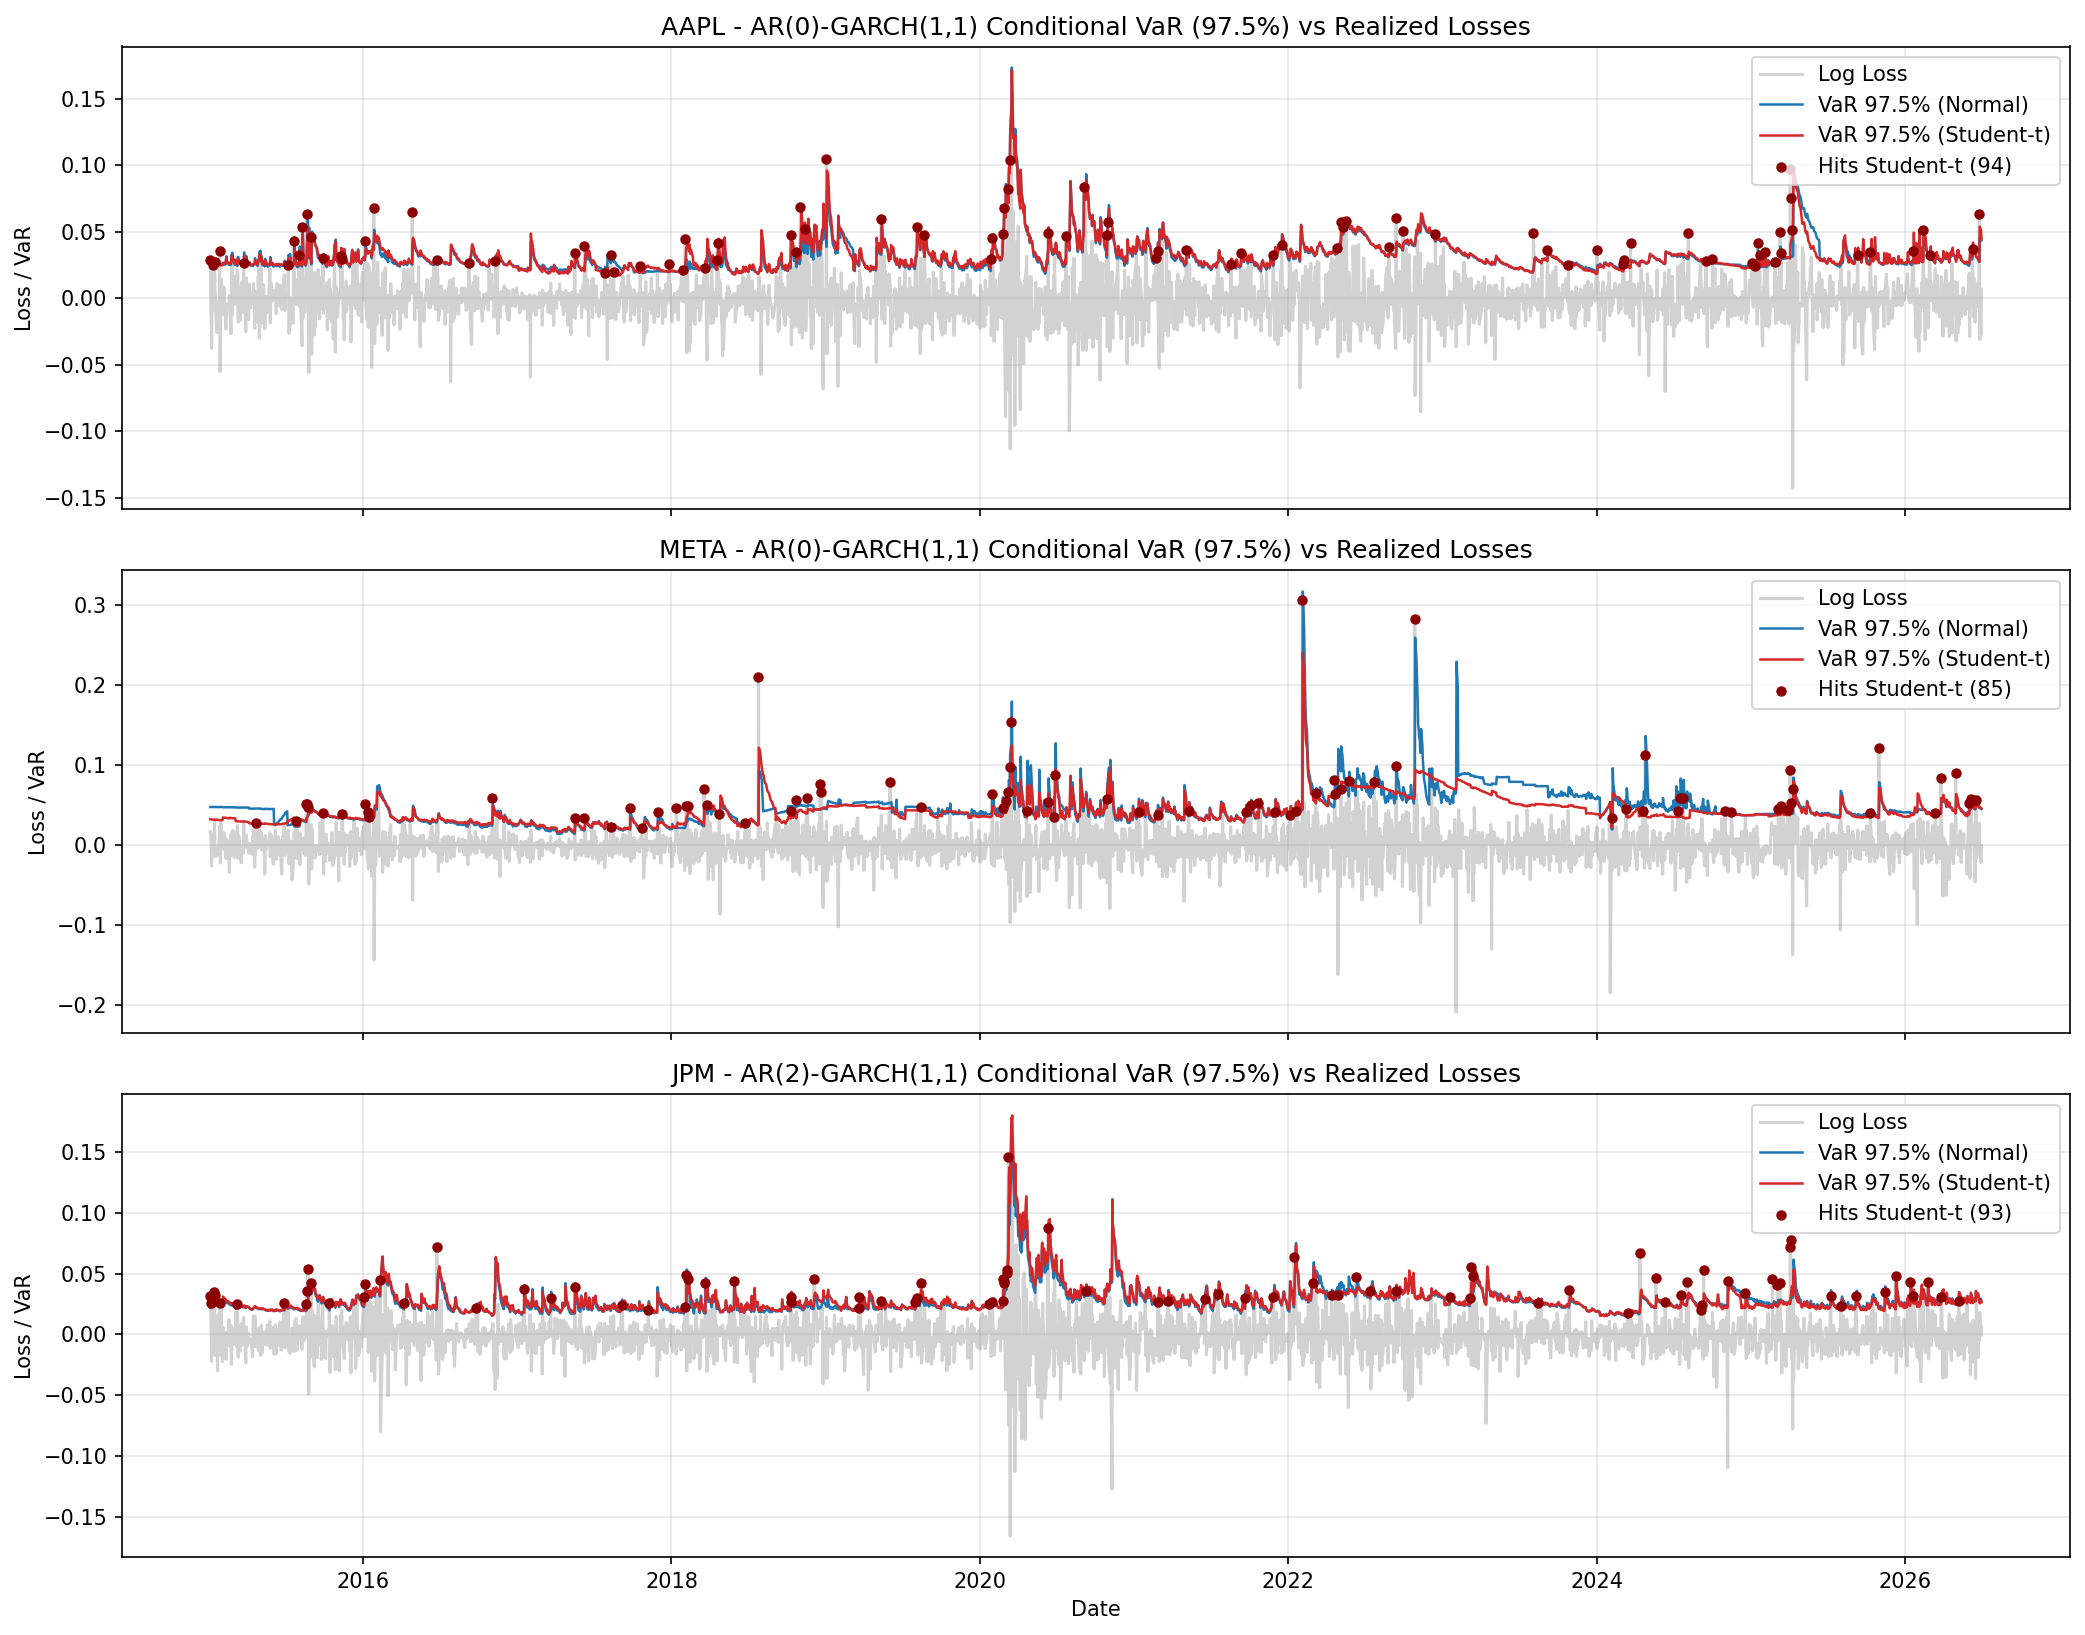

In [16]:
# Visualizations: Conditional VaR & Volatility Forecasts with Exceedances
plt.rcParams["figure.dpi"] = 150

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

for i, ticker in enumerate(TICKERS):
    ax = axes[i]
    loss_series = eval_loss[ticker]
    var_n_975 = garch_var[(ticker, "normal", 0.975)]
    var_t_975 = garch_var[(ticker, "t", 0.975)]

    hits_t = loss_series > var_t_975

    ax.plot(loss_series.index, loss_series, color="gray", alpha=0.35, label="Log Loss")
    ax.plot(var_n_975.index, var_n_975, color="tab:blue", lw=1.2, label="VaR 97.5% (Normal)")
    ax.plot(var_t_975.index, var_t_975, color="tab:red", lw=1.2, label="VaR 97.5% (Student-t)")
    ax.scatter(loss_series.index[hits_t], loss_series[hits_t], color="darkred", s=16, zorder=4, label=f"Hits Student-t ({hits_t.sum()})")

    ax.set_ylabel("Loss / VaR")
    ax.set_title(f"{ticker} - AR({best_p[ticker]})-GARCH(1,1) Conditional VaR (97.5%) vs Realized Losses")
    ax.legend(loc="upper right", frameon=True)
    ax.grid(True, alpha=0.3)

plt.xlabel("Date")
plt.tight_layout()
plt.show()


## Question 5 -- Quantile regression

Same evaluation period, window and refit days as Question 4. One model per stock and level, VaR only;
the two features are built by `make_features` below, both using information up to $t-1$; the target
is the loss $L_t$. Rows with an undefined feature (the first 20 days) are dropped from the training
window. Linear quantile regression, e.g.
`sm.QuantReg(y, sm.add_constant(X)).fit(q=alpha, max_iter=5000)`.

In [17]:
# Question 5
import statsmodels.api as sm


def make_features(ret: pd.Series) -> pd.DataFrame:
    """Features x_{t-1} for the forecast of day t: row t uses information up to t-1 only."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat


# After (a) and (b): the combined VaR backtest table, one table per level
# backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()


### Calculation

In [18]:
forecasts = {}

for alpha in ALPHAS:

    forecasts[alpha] = pd.DataFrame(
        index=returns.index, columns=returns.columns, dtype=float
    )

    for t in TICKERS:

        features = make_features(returns[t])

        result = None

        for j in range(WINDOW, len(returns)):

            if (j - WINDOW) % REFIT == 0:

                X = features.iloc[j - WINDOW : j].dropna()
                y = losses[t].loc[X.index].values

                result = sm.QuantReg(y, sm.add_constant(X)).fit(q=alpha, max_iter=20000)

            x = features.iloc[j]
            x = np.insert(x.values, 0, 1)

            forecasts[alpha].loc[returns.index[j], t] = x @ result.params

In [19]:
forecasts[0.975]

,AAPL,META,JPM
Date,,,
2013-01-03,NaN,NaN,NaN
2013-01-04,NaN,NaN,NaN
2013-01-07,NaN,NaN,NaN
2013-01-08,NaN,NaN,NaN
2013-01-09,NaN,NaN,NaN
...,...,...,...
2026-06-24,0.032851,0.043798,0.029104
2026-06-25,0.030698,0.044620,0.024105
2026-06-26,0.057856,0.047324,0.027605


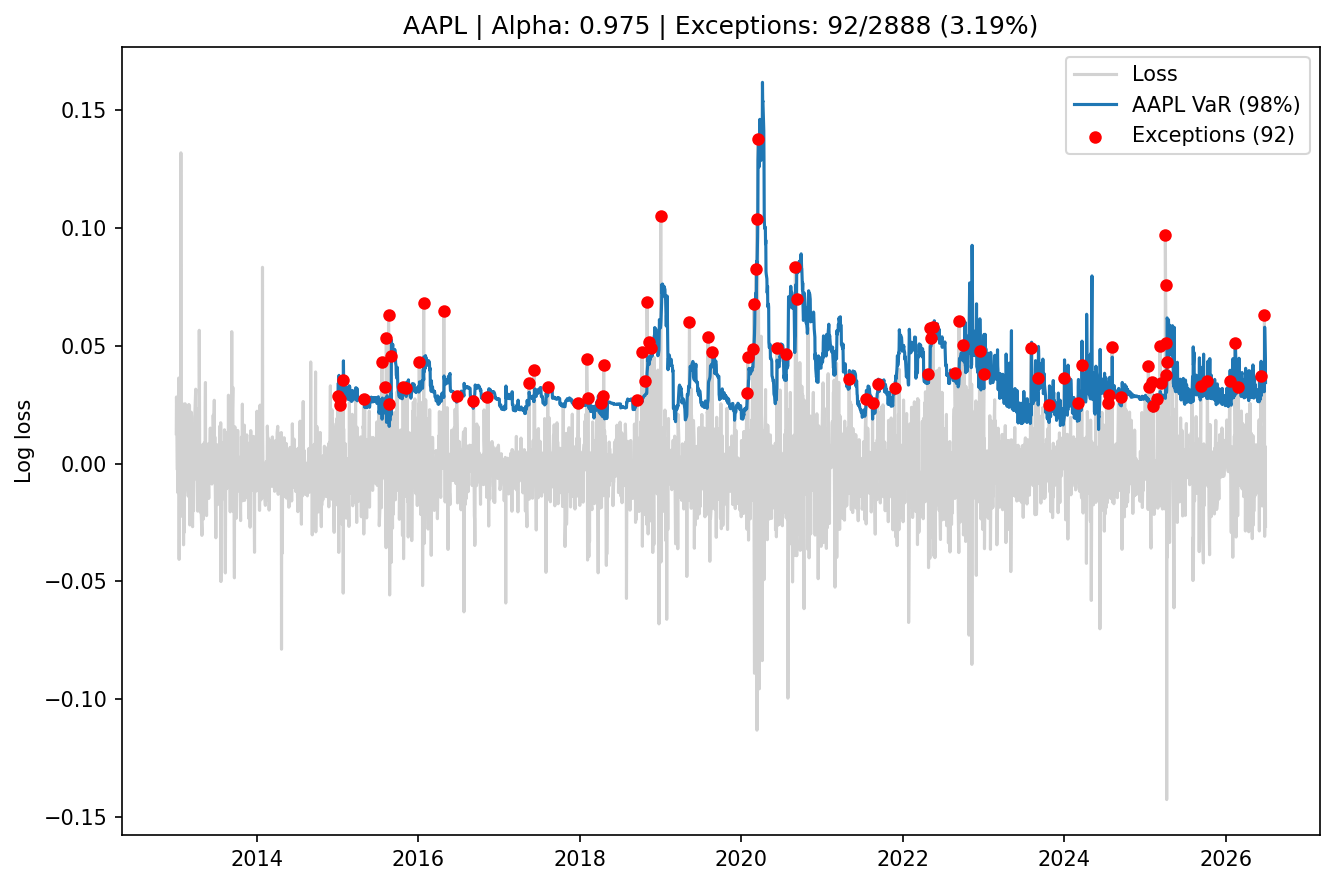

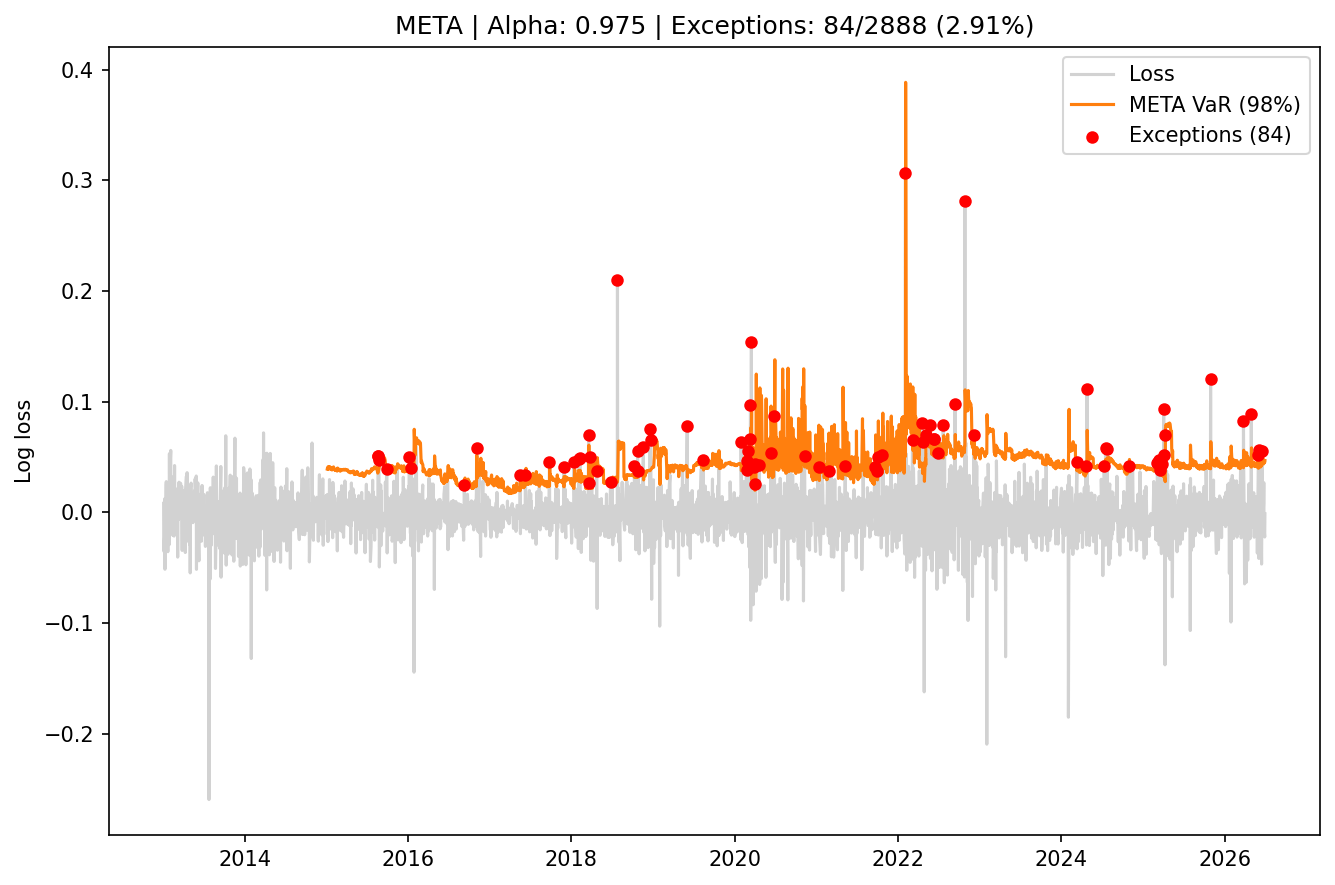

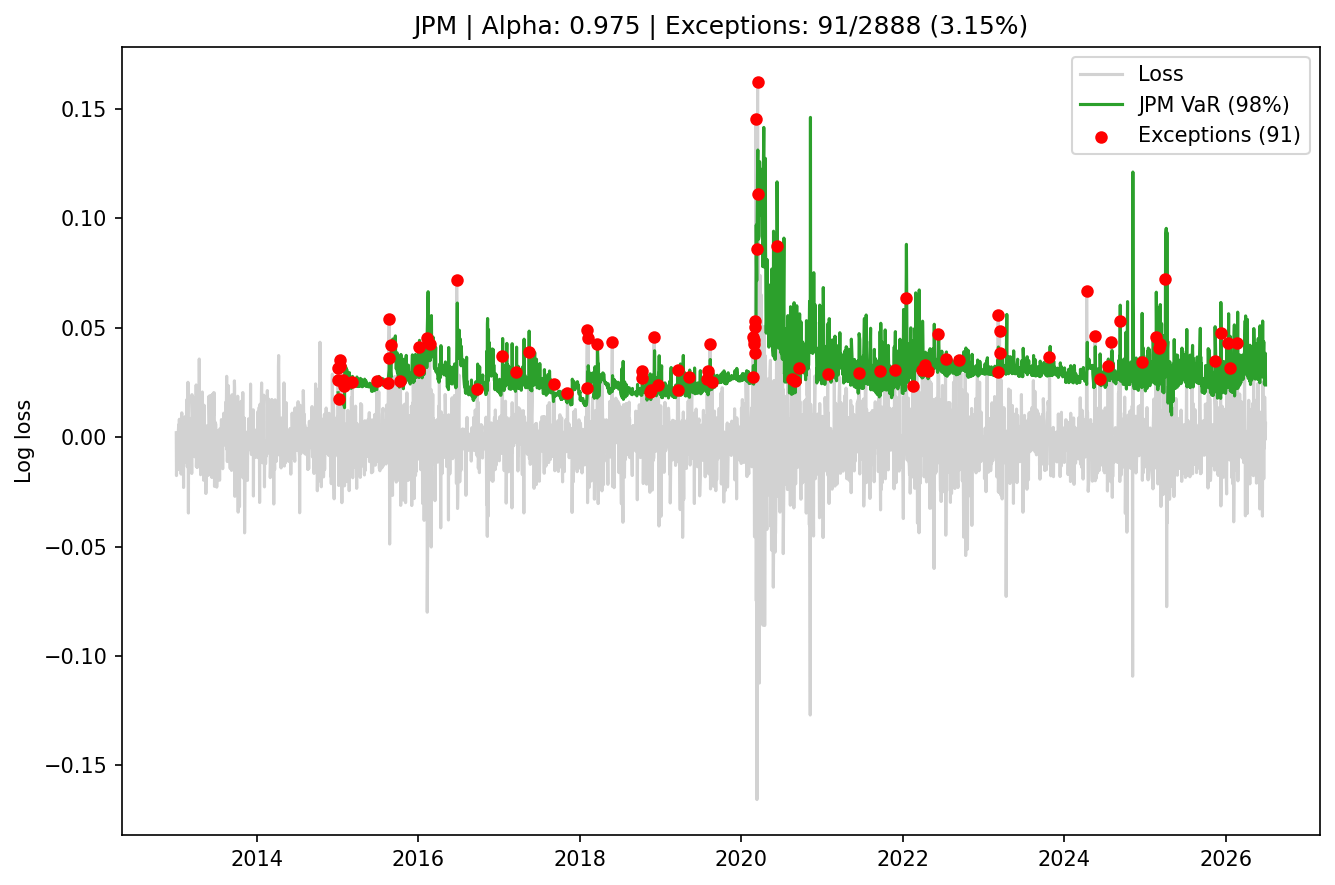

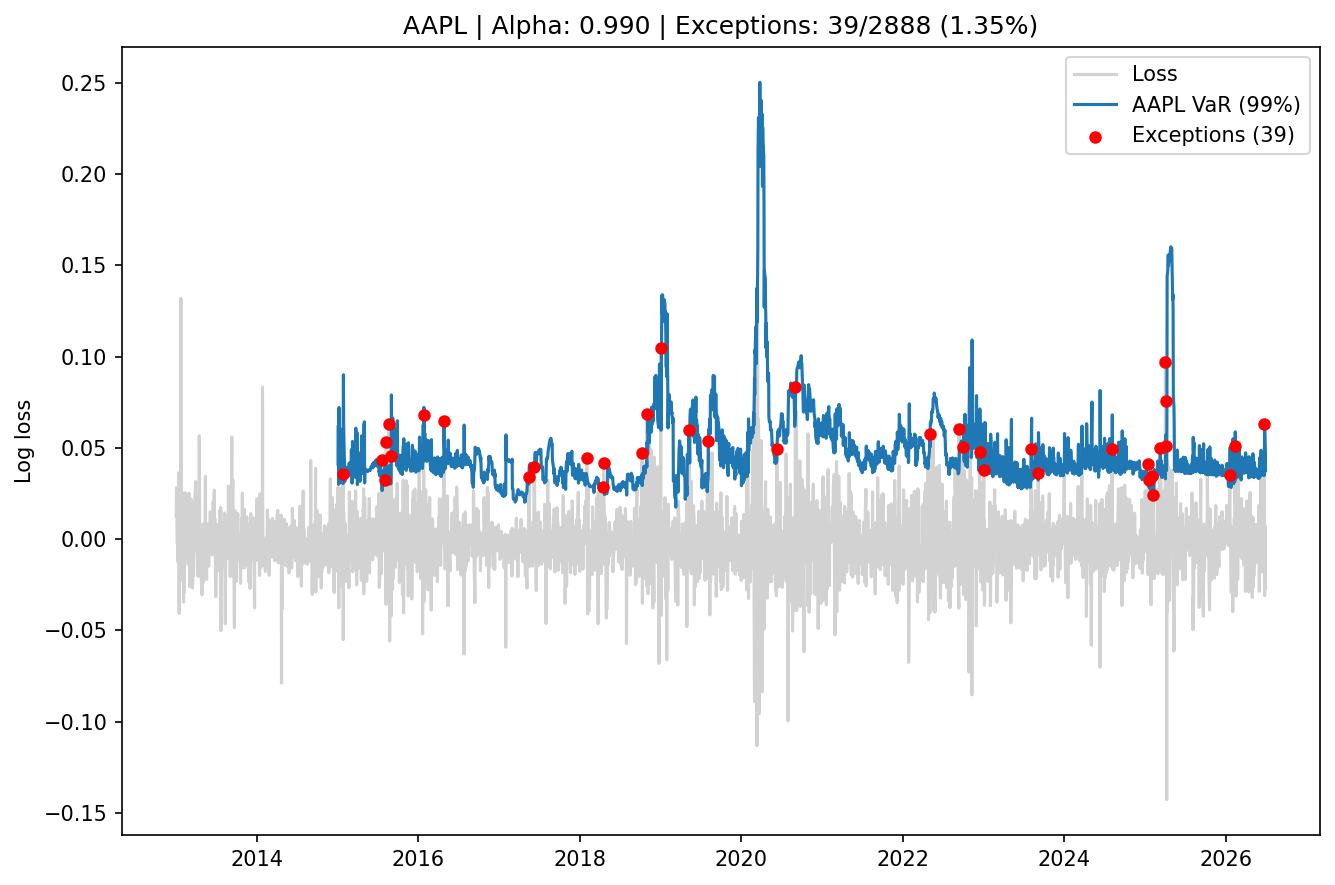

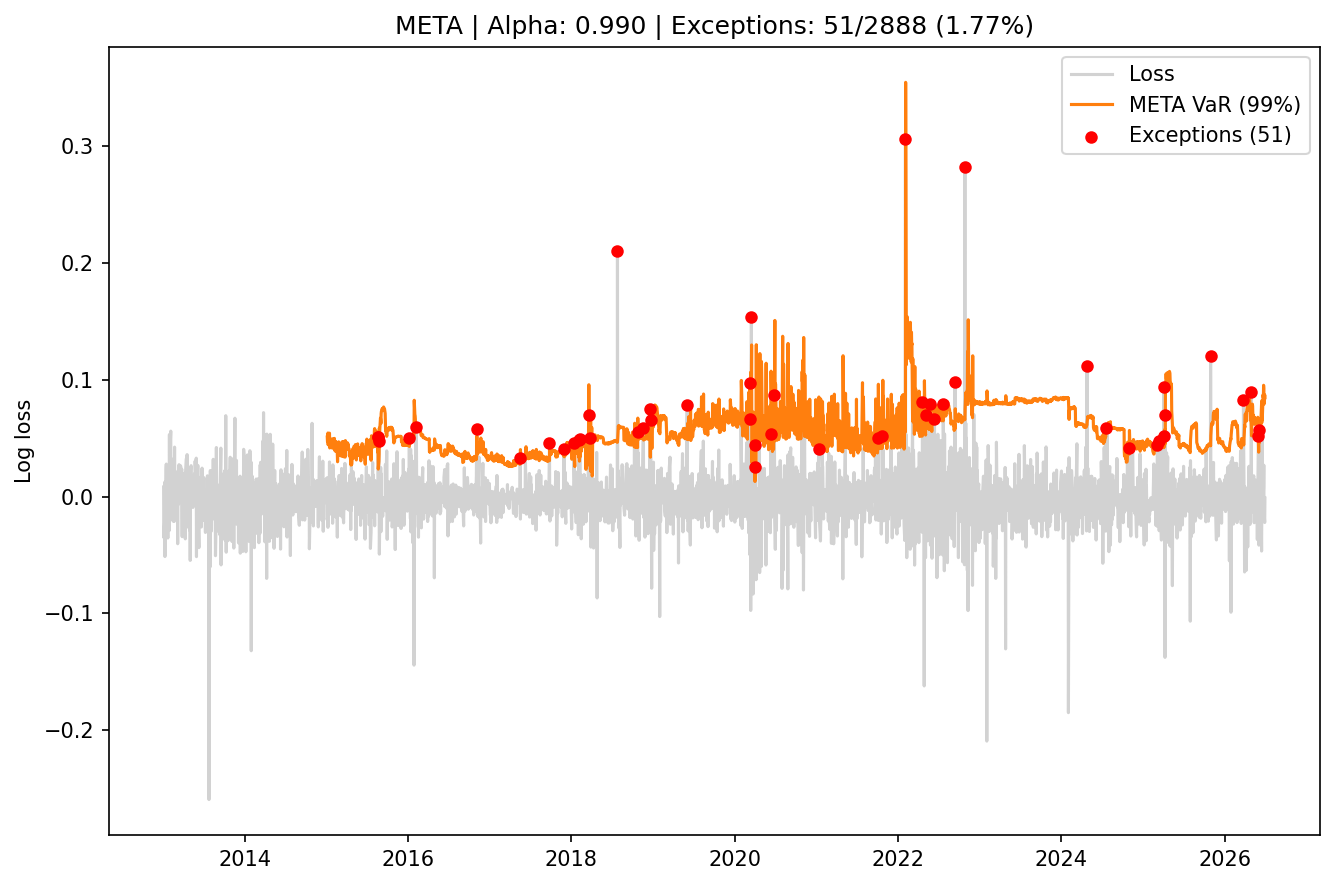

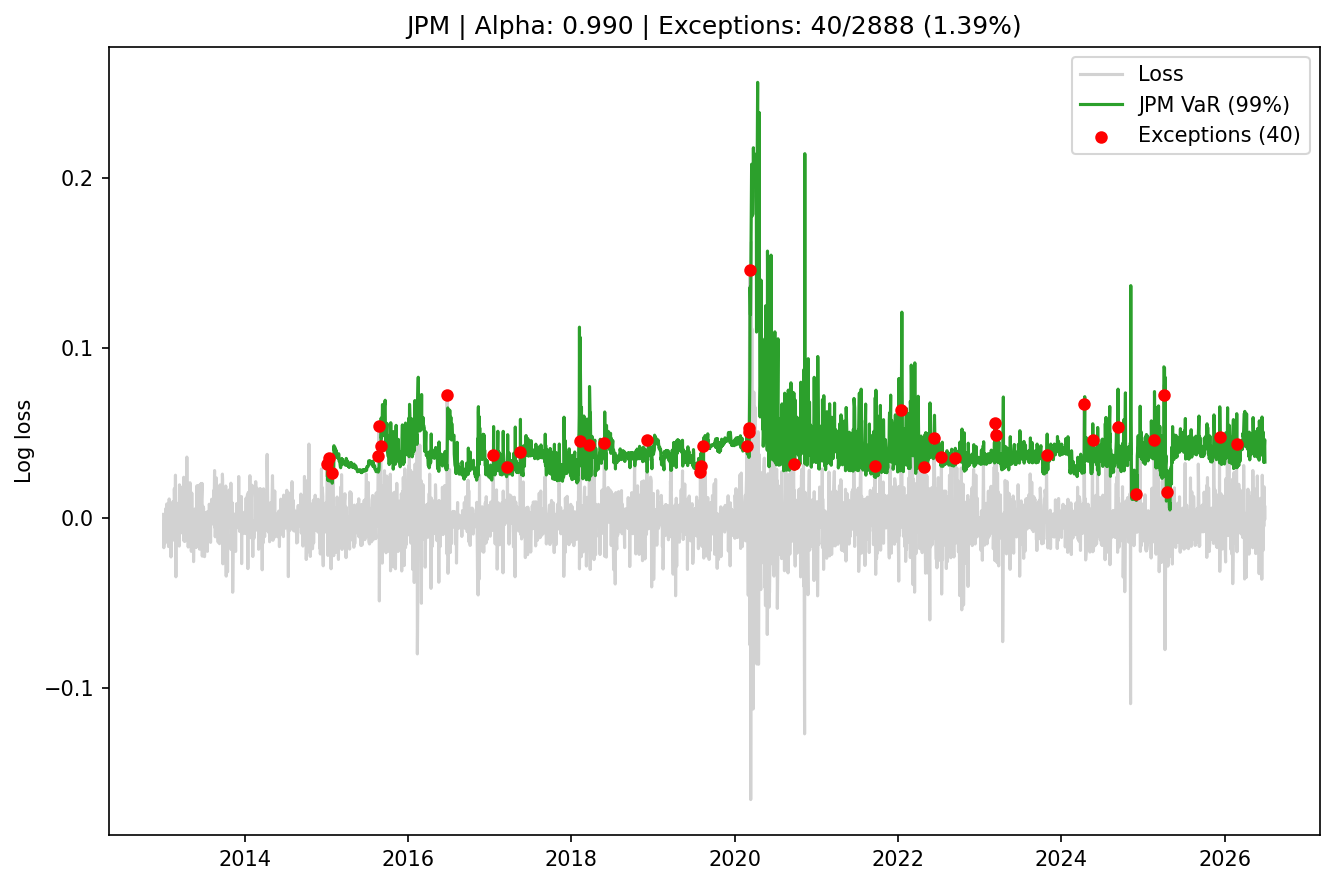

In [20]:
colors = ['C0', 'C1', 'C2']

for alpha in ALPHAS:

    for i, t in enumerate(TICKERS):

        var = forecasts[alpha][t]

        exceptions = (losses[t] > var) & var.notna()

        n_exceptions = exceptions.sum()
        n_valid = var.notna().sum()

        plt.figure(figsize=(9, 6))

        plt.plot(
            losses[t].index,
            losses[t],
            color='grey',
            alpha=0.35,
            label="Loss"
        )

        plt.plot(
            var.index,
            var,
            color=colors[i % len(colors)],
            label=f"{t} VaR ({alpha:.0%})"
        )

        plt.scatter(
            losses[t].index[exceptions],
            losses[t][exceptions],
            color='red',
            s=25,
            label=f"Exceptions ({n_exceptions})",
            zorder=3
        )

        plt.ylabel("Log loss")
        plt.title(
            f"{t} | Alpha: {alpha:.3f} | "
            f"Exceptions: {n_exceptions}/{n_valid} "
            f"({100*n_exceptions/n_valid:.2f}%)"
        )

        plt.legend()
        plt.tight_layout()
        plt.show()

### Quantile crossing

In [21]:
for t in TICKERS:

    print(f"\n{'='*40}\n{t}\n{'='*40}")

    for i, alpha1 in enumerate(ALPHAS):

        for alpha2 in ALPHAS[i + 1 :]:

            comparison = pd.concat(
                [
                    forecasts[alpha1][t].rename("alpha1"),
                    forecasts[alpha2][t].rename("alpha2"),
                ],
                axis=1,
            ).dropna()

            above = comparison.alpha1 > comparison.alpha2
            below = comparison.alpha1 < comparison.alpha2
            equal = comparison.alpha1 == comparison.alpha2

            n = len(comparison)

            print(
                f"Alpha {alpha1:.3f} vs {alpha2:.3f}: "
                f"{above.sum()} days ({above.mean():.2%}) "
                f"where {alpha1:.3f} > {alpha2:.3f}; "
                f"{below.sum()} days ({below.mean():.2%}) "
                f"where {alpha1:.3f} < {alpha2:.3f}; "
                f"{equal.sum()} equal days. "
                f"Total: {n}"
            )


AAPL
Alpha 0.975 vs 0.990: 43 days (1.49%) where 0.975 > 0.990; 2845 days (98.51%) where 0.975 < 0.990; 0 equal days. Total: 2888

META
Alpha 0.975 vs 0.990: 186 days (6.44%) where 0.975 > 0.990; 2702 days (93.56%) where 0.975 < 0.990; 0 equal days. Total: 2888

JPM
Alpha 0.975 vs 0.990: 105 days (3.64%) where 0.975 > 0.990; 2783 days (96.36%) where 0.975 < 0.990; 0 equal days. Total: 2888


### Adding results to the backtest table

In [22]:
# Question 5(a): Backtest both models and add them to the two tables
print("=" * 80)
print("Question 5(a): Backtesting Results (Kupiec, Christoffersen, Pinball, Acerbi-Szekely, Fissler-Ziegel)")
print("=" * 80)

for ticker in TICKERS:
    actual_loss = eval_loss[ticker].values
    N = len(actual_loss)

    method_name = "QuantReg"

    # VaR Backtesting for each alpha level
    for alpha in ALPHAS:
        var_vals = forecasts[alpha][ticker].dropna()
        hits = (actual_loss > var_vals)
        x = int(np.sum(hits))
        expected = N * (1.0 - alpha)
        hit_rate = x / N

        _, p_uc = kupiec_uc(hits, alpha)
        _, p_ind = christoffersen_ind(hits)
        _, p_cc = christoffersen_cc(hits, alpha)
        pinball_bp = pinball_loss_bp(actual_loss, var_vals, alpha)

        backtest_rows.append({
            "stock": ticker,
            "method": method_name,
            "alpha": alpha,
            "x": x,
            "expected": expected,
            "hit": hit_rate,
            "p_uc": p_uc,
            "p_ind": p_ind,
            "p_cc": p_cc,
            "pinball_bp": pinball_bp,
        })


print("\n--- Combined VaR Backtest Table (Questions 3-5 rows so far) ---")
q5_backtest_df = pd.DataFrame(backtest_rows)
display(q5_backtest_df)


Question 5(a): Backtesting Results (Kupiec, Christoffersen, Pinball, Acerbi-Szekely, Fissler-Ziegel)

--- Combined VaR Backtest Table (Questions 3-5 rows so far) ---


,stock,method,alpha,x,expected,hit,p_uc,p_ind,p_cc,pinball_bp
0,AAPL,HS,0.975,86,72.20,0.029778,1.101693e-01,4.478473e-03,4.915692e-03,13.600955
1,AAPL,HS,0.990,41,28.88,0.014197,3.299351e-02,1.378501e-01,3.425387e-02,7.244271
2,AAPL,Gaussian,0.975,105,72.20,0.036357,2.472590e-04,4.065558e-04,2.335407e-06,13.751009
3,AAPL,Gaussian,0.990,63,28.88,0.021814,3.431187e-08,1.351148e-02,1.158072e-08,7.662157
4,AAPL,Student-t,0.975,103,72.20,0.035665,5.530672e-04,6.200267e-05,8.448838e-07,13.715665
5,AAPL,Student-t,0.990,41,28.88,0.014197,3.299351e-02,1.378501e-01,3.425387e-02,7.211154
6,META,HS,0.975,75,72.20,0.025970,7.401494e-01,1.550802e-02,5.059483e-02,18.261721
7,META,HS,0.990,40,28.88,0.013850,4.939976e-02,1.252902e-01,4.478807e-02,10.372436
8,META,Gaussian,0.975,78,72.20,0.027008,4.948864e-01,2.195534e-04,8.580230e-04,18.320949
9,META,Gaussian,0.990,52,28.88,0.018006,1.014632e-04,2.300373e-03,5.024843e-06,10.675281


## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [23]:
# Question 6
from scipy.stats import genpareto
full_loss = losses                          # one column per stock


### 6.b)

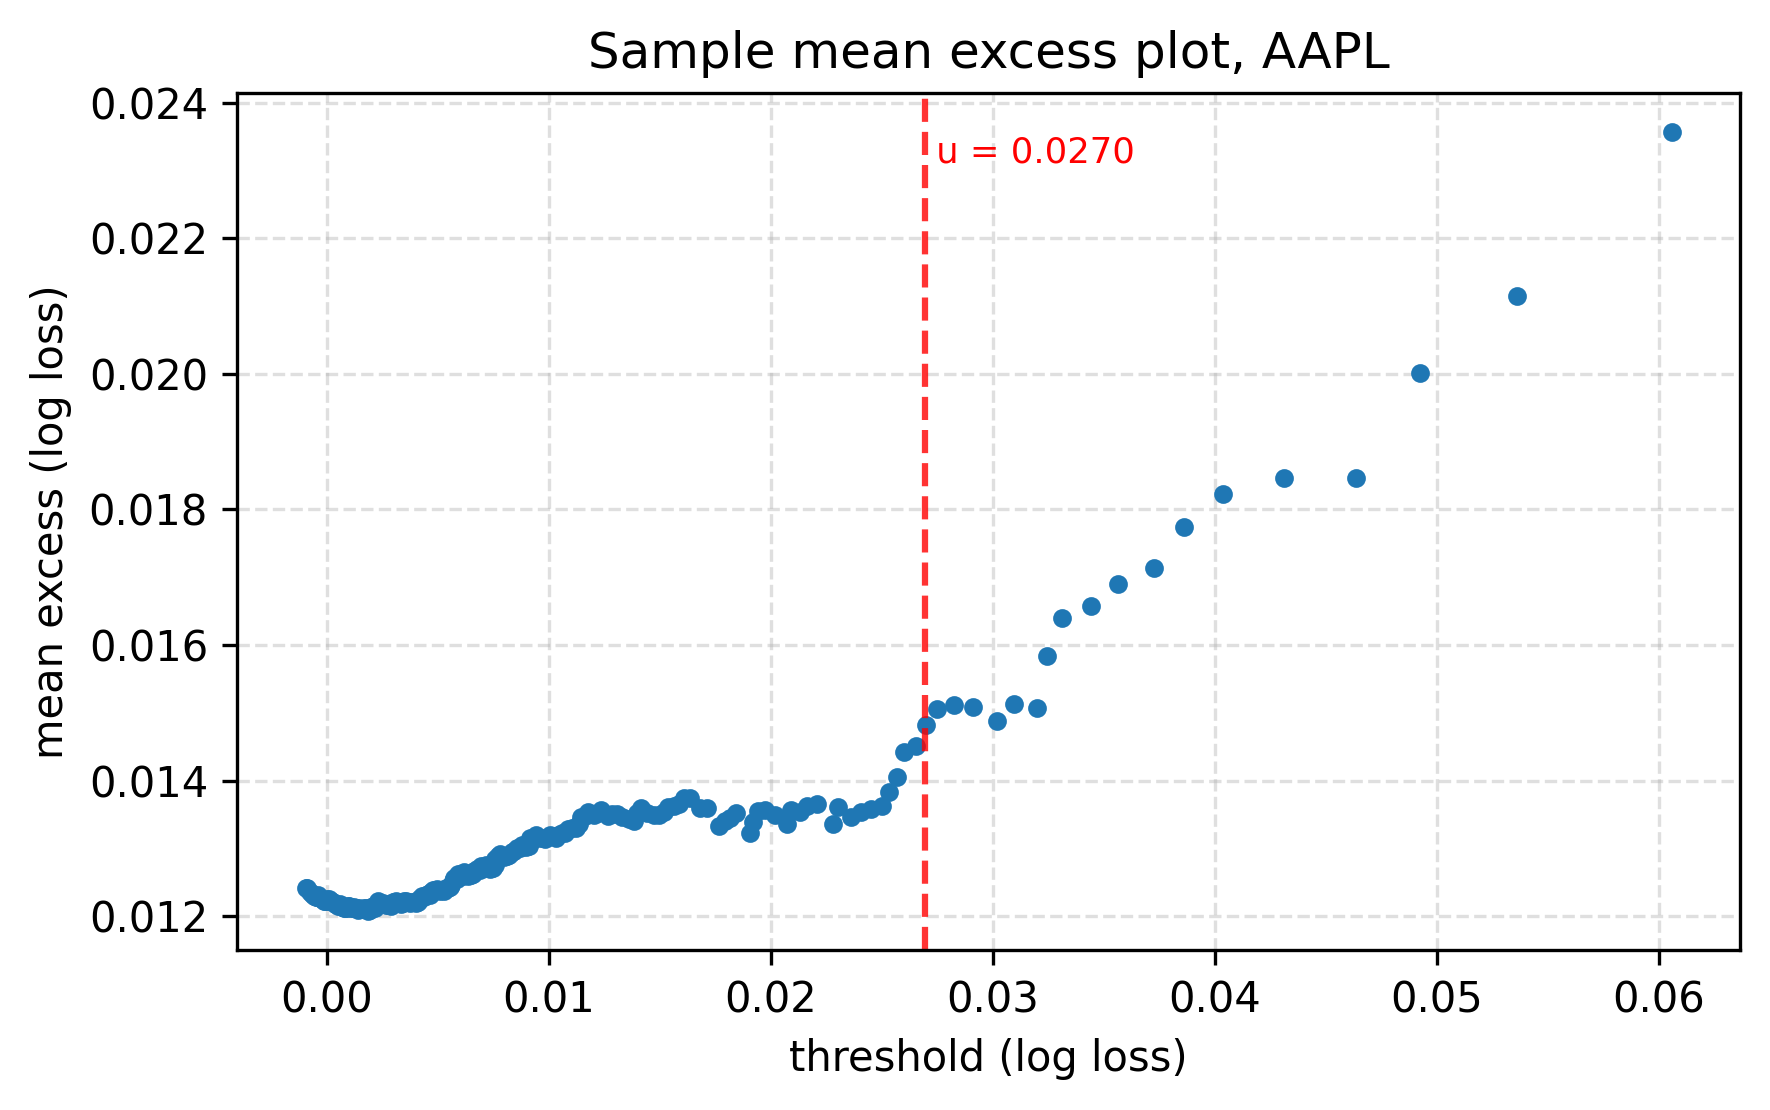

AAPL: u = 0.026972, N_u = 170


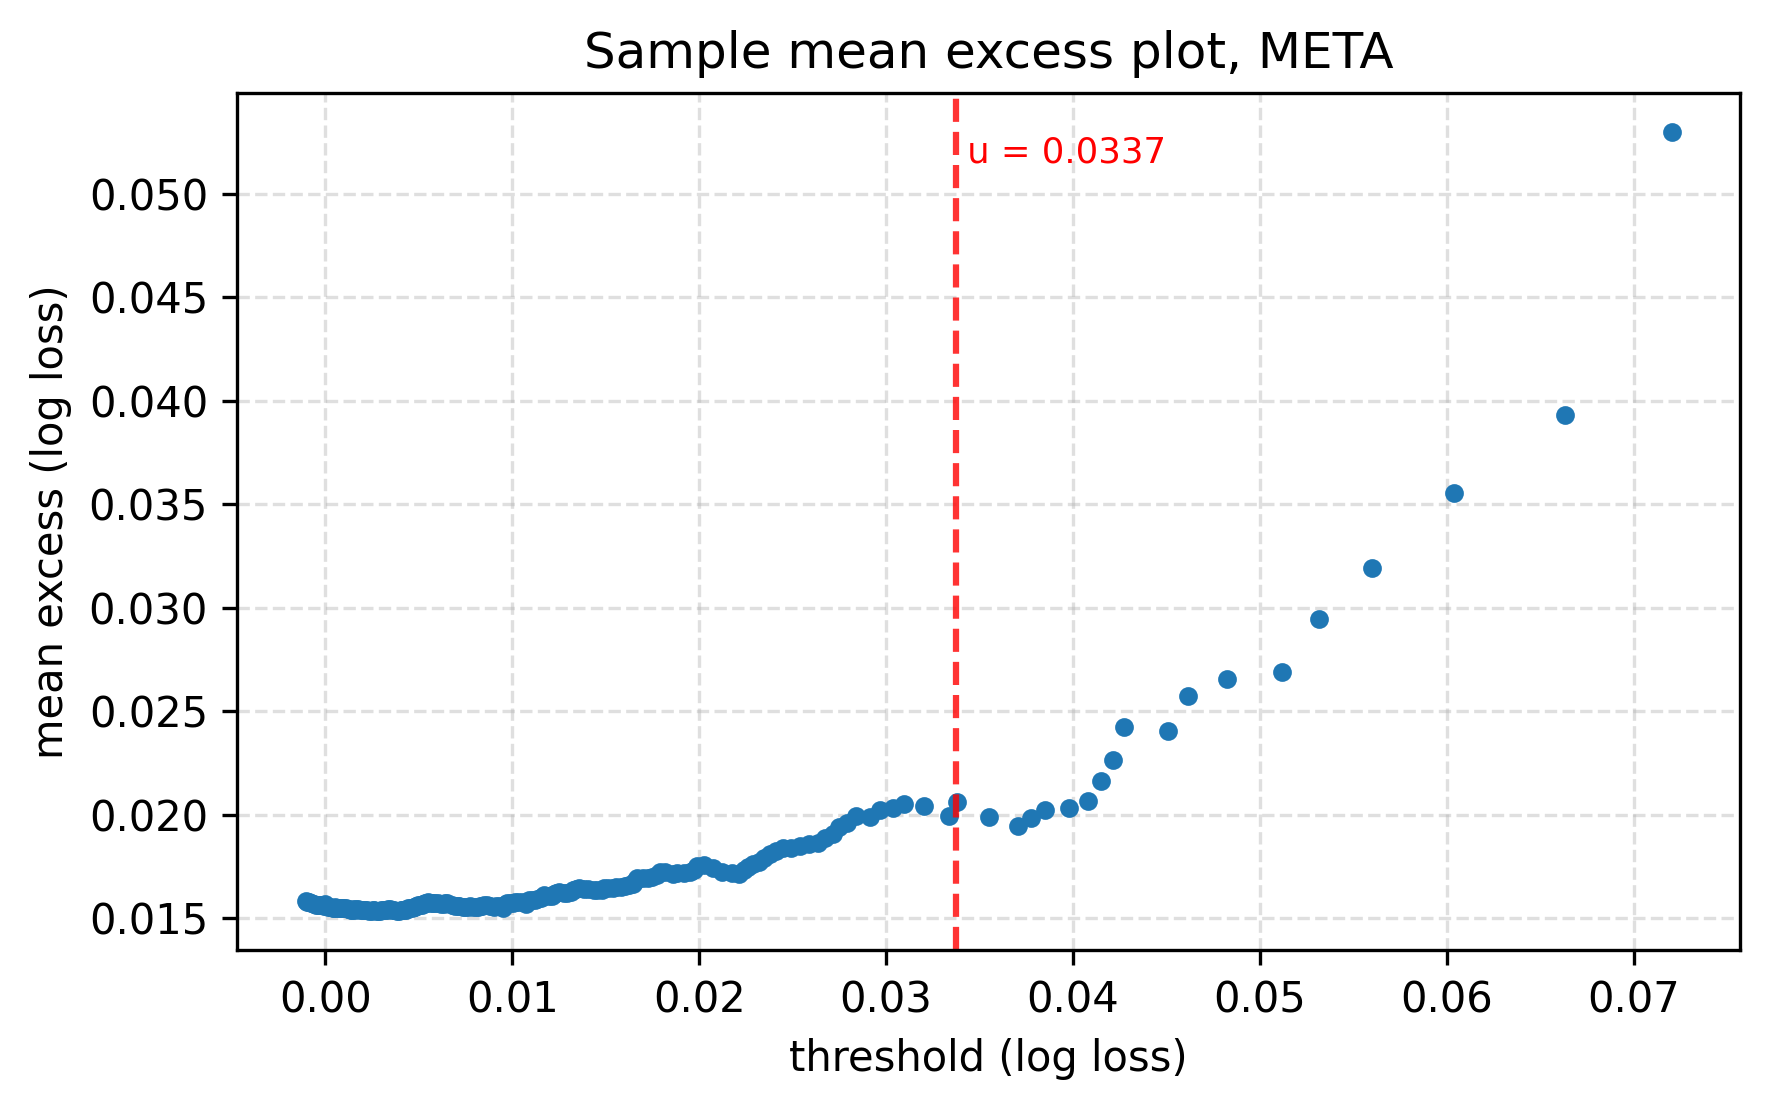

META: u = 0.033738, N_u = 170


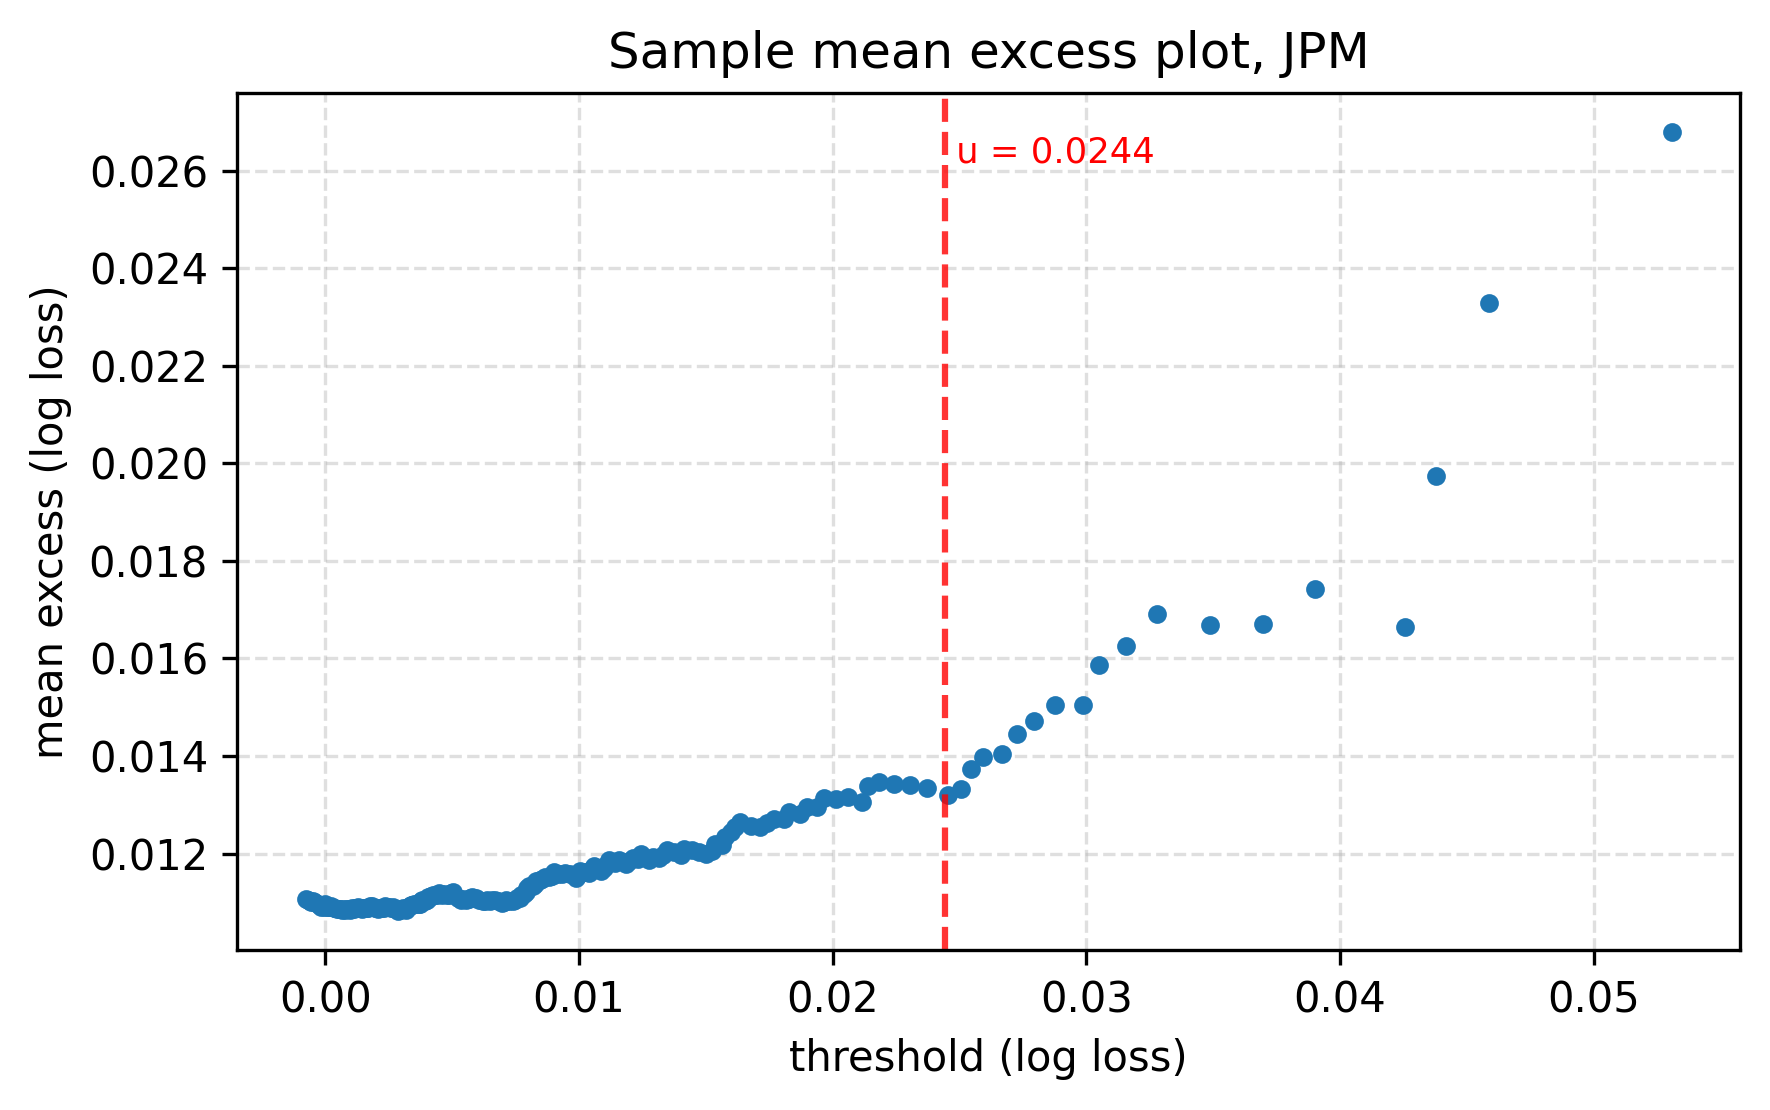

JPM: u = 0.024411, N_u = 170


In [24]:
# Set global figure quality
plt.rcParams["figure.dpi"] = 300

alpha_threshold = 0.95

for c in full_loss.columns:
    x = np.sort(full_loss[c])

    threshold = np.quantile(x, alpha_threshold)

    u_grid = np.quantile(x, np.linspace(0.50, 0.995, 200))
    me = np.array(
        [(x[x > u] - u).mean() if np.sum(x > u) > 1 else np.nan for u in u_grid]
    )

    # High-quality figure sizing and styling (slightly smaller)
    fig, ax = plt.subplots(figsize=(6, 3.8))
    ax.scatter(u_grid, me, s=16, linewidth=0.5, zorder=2)

    # Add vertical red line at threshold
    ax.axvline(x=threshold, color="red", linestyle="--", linewidth=1.5, alpha=0.8)

    # Mark the 95% quantile in red near the top of the line
    ax.text(
        threshold,
        0.95,
        f" u = {threshold:.4f}",
        color="red",
        fontsize=8.5,
        ha="left",
        va="top",
        transform=ax.get_xaxis_transform(),
        zorder=3,
    )

    ax.set_xlabel("threshold (log loss)")
    ax.set_ylabel("mean excess (log loss)")
    ax.set_title(f"Sample mean excess plot, {c}")

    ax.grid(True, linestyle="--", alpha=0.4, zorder=1)
    fig.tight_layout()
    plt.show()

    exceedances = x[x > threshold] - threshold
    print(f"{c}: u = {threshold:.6f}, N_u = {len(exceedances)}")

### 6.c)

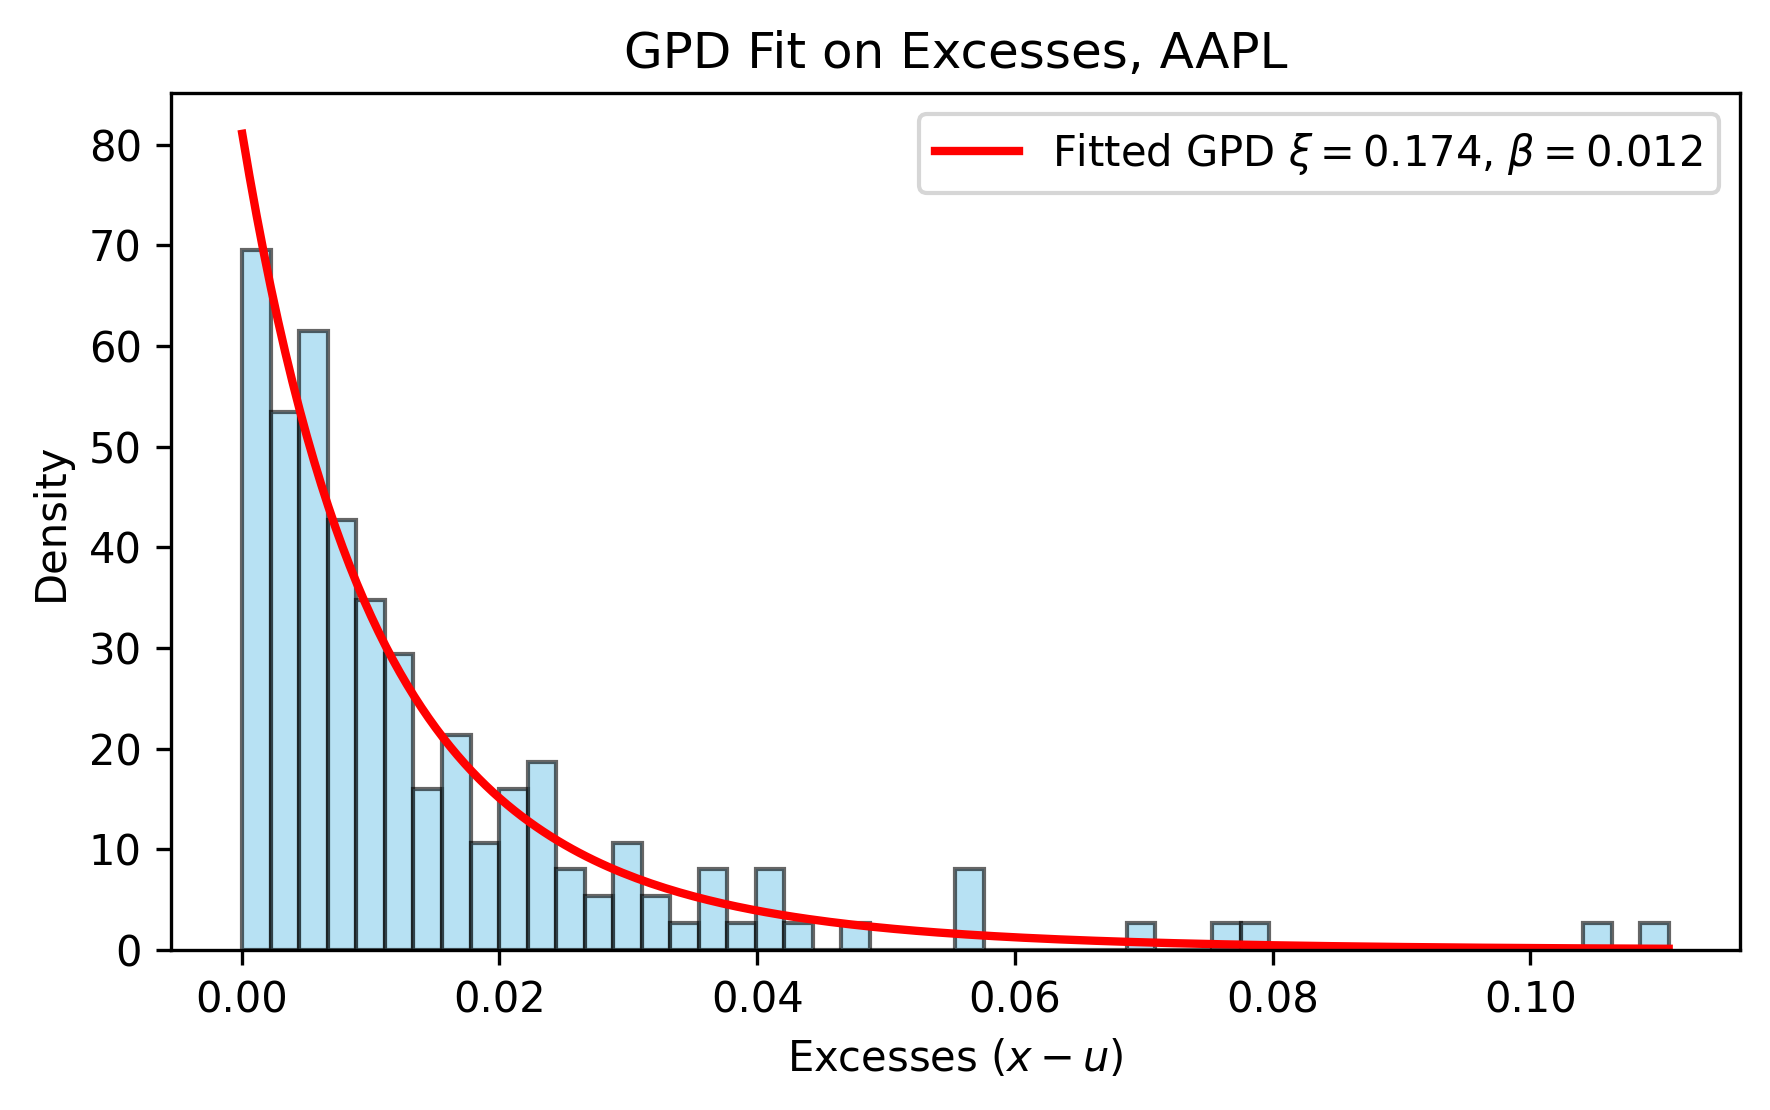

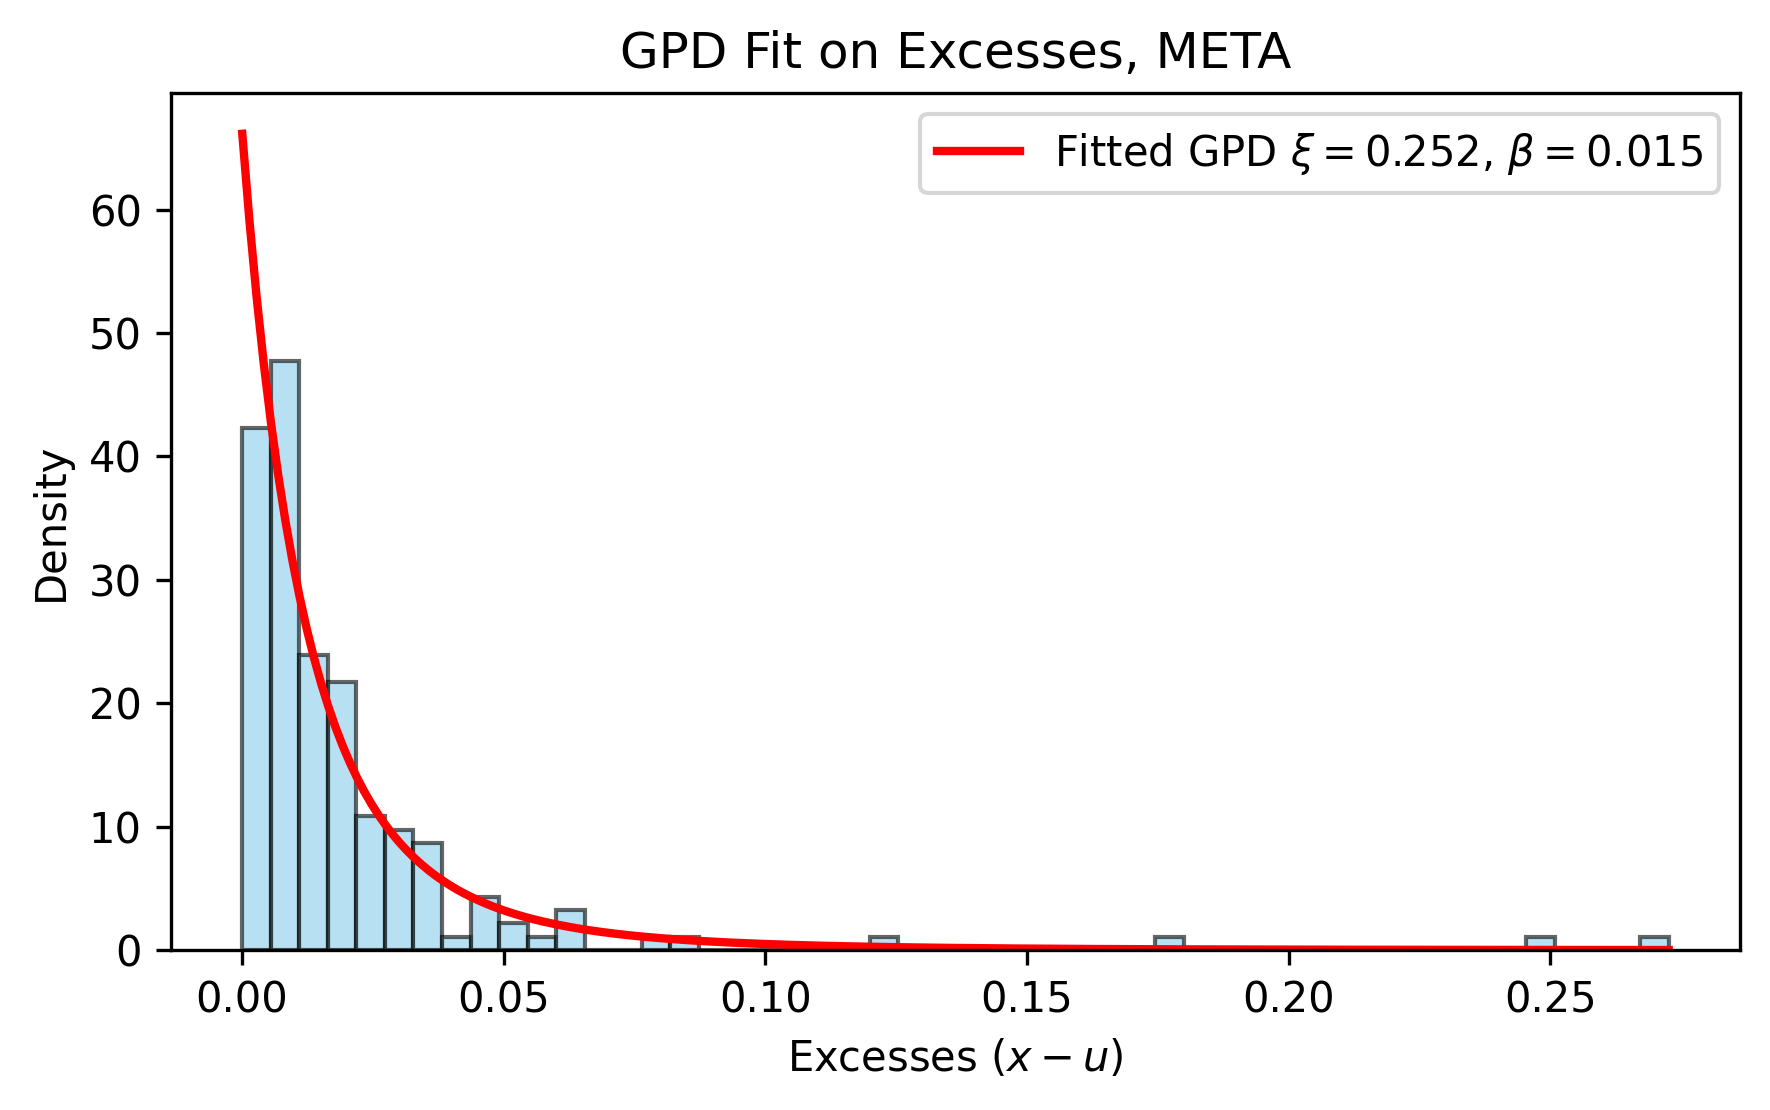

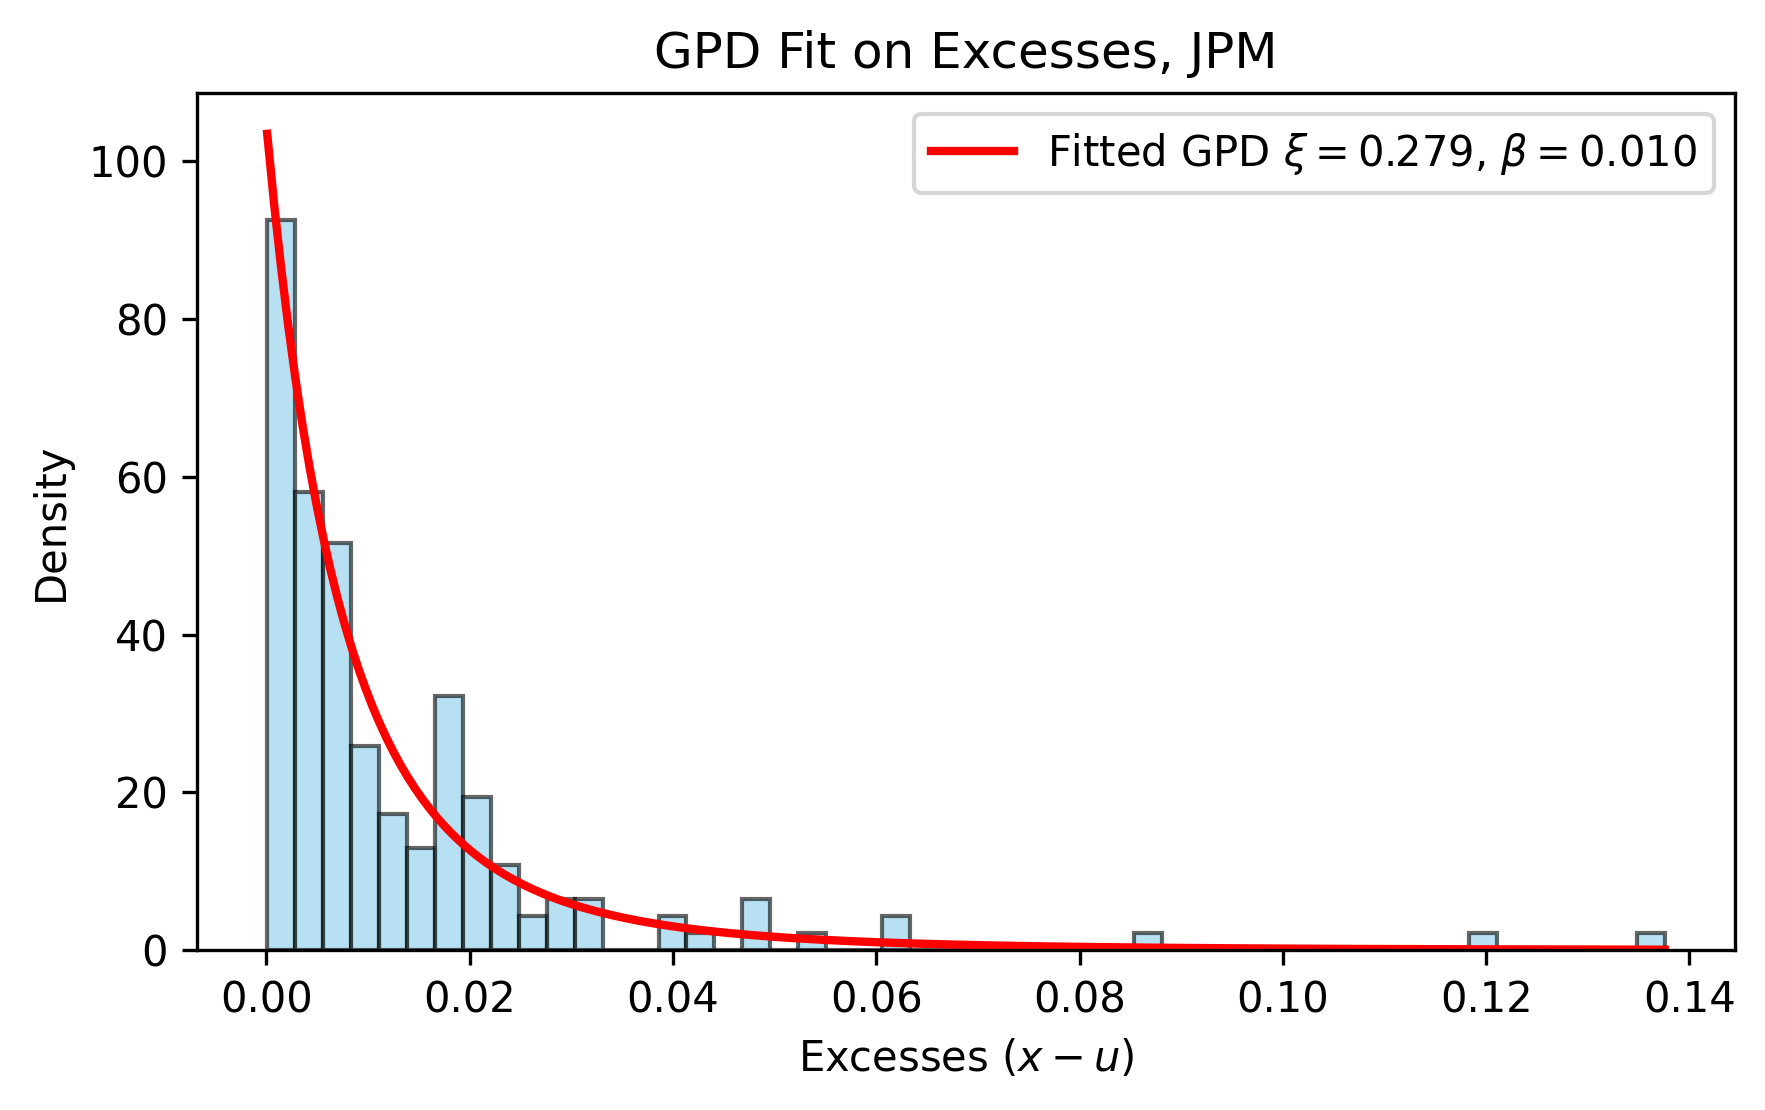

In [25]:
# Set global figure quality
plt.rcParams['figure.dpi'] = 300

alpha_threshold = 0.95

for c in full_loss.columns:
    x = np.sort(full_loss[c])

    k = int(np.ceil(alpha_threshold * len(x)) - 1) # -1 for 0 based indexing
    threshold = x[k]

    excedances = x[x > threshold] - threshold

    xi, _, beta = genpareto.fit(excedances, floc=0)

    def gpd(x):
        return stats.genpareto.pdf(x, xi, loc=0, scale=beta)

    plt.figure(figsize=(6, 3.8))
    counts, bin_edges, patches = plt.hist(excedances, bins=50, density=True, alpha=0.6, color='skyblue', edgecolor='black')

    x_smooth = np.linspace(bin_edges[0], bin_edges[-1], 200)
    # Capped float representation to 3 decimals using format specifiers
    plt.plot(x_smooth, gpd(x_smooth), 'r-', linewidth=2, label=f'Fitted GPD $\\xi=${xi:.3f}, $\\beta=${beta:.3f}')

    plt.xlabel('Excesses ($x - u$)')
    plt.ylabel('Density')
    plt.title(f'GPD Fit on Excesses, {c}')
    plt.legend()
    plt.tight_layout()
    plt.show()

### 6.d)

In [26]:
# Set global figure quality
plt.rcParams['figure.dpi'] = 300

VaR_storage = np.zeros(3)
ES_storage = np.zeros(3)

alpha_threshold = 0.95

for i, c in enumerate(full_loss.columns):
    x = np.sort(full_loss[c])

    k = int(np.ceil(alpha_threshold * len(x)) - 1) # -1 for 0 based indexing
    u = x[k]

    excedances = x[x > u] - u
    Nu = len(excedances)

    xi, _, beta = genpareto.fit(excedances, floc=0)

    print(f'======= {c} =======')
    VaR = u + beta / xi * ((1000 * (1 - DEEP_ALPHA) / Nu) ** (- xi) - 1)
    num_VaR_excedances = len(x[x > VaR])
    expected_VaR_excedances = (1 - DEEP_ALPHA) * len(x)
    print(f'VaR_{DEEP_ALPHA} = {VaR:.3f}, exceeded {num_VaR_excedances} days (expected {expected_VaR_excedances:.1f})')
    VaR_storage[i] = VaR
    
    ES = VaR / (1 - xi) + (beta - xi * u) / (1 - xi)
    num_ES_excedances = len(x[x > ES])
    print(f'ES_{DEEP_ALPHA} = {ES:.3f}, exceeded {num_ES_excedances} days')
    ES_storage[i] = ES

======= AAPL =======
VaR_0.999 = 0.129, exceeded 2 days (expected 3.4)
ES_0.999 = 0.165, exceeded 0 days
======= META =======
VaR_0.999 = 0.191, exceeded 3 days (expected 3.4)
ES_0.999 = 0.265, exceeded 2 days
======= JPM =======
VaR_0.999 = 0.134, exceeded 2 days (expected 3.4)
ES_0.999 = 0.189, exceeded 0 days


### 6.e)

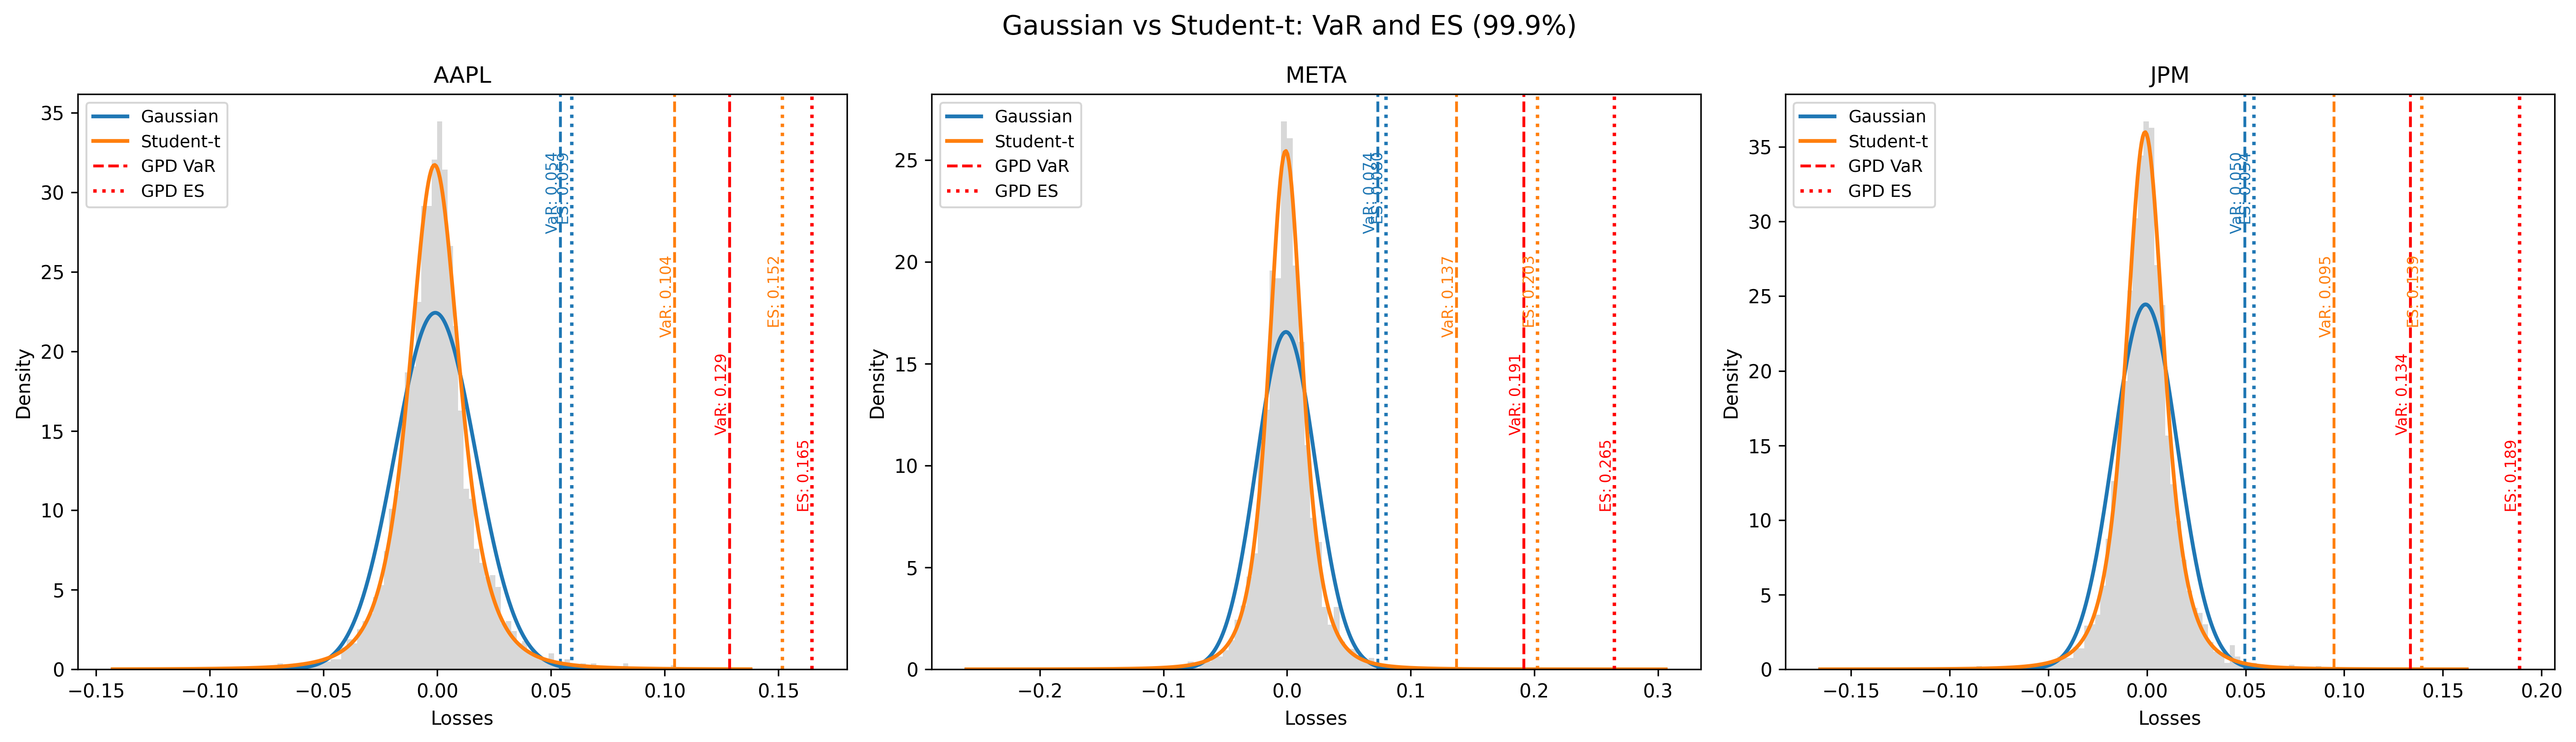

,Stock,Method,VaR,ES
0,AAPL,Gaussian,0.05413,0.05906
1,AAPL,Student-t,0.10424,0.15168
2,AAPL,GPD,0.12852,0.16471
3,META,Gaussian,0.07355,0.08022
4,META,Student-t,0.13706,0.20270
5,META,GPD,0.19144,0.26475
6,JPM,Gaussian,0.04973,0.05425
7,JPM,Student-t,0.09479,0.13929
8,JPM,GPD,0.13350,0.18885


In [27]:
alpha = 0.999

# GPD results: ordered according to TICKERS[:3]
gpd_var = VaR_storage
gpd_es = ES_storage

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

results = []

for ax, ticker, gpd_v, gpd_e in zip(axes, TICKERS[:3], gpd_var, gpd_es):

    data = losses[ticker].dropna()
    xx = np.linspace(data.min(), data.max(), 500)

    # Histogram
    ax.hist(data, bins=120, density=True, alpha=0.30, color="grey")

    # ==========================
    # Gaussian
    # ==========================
    mu_g = data.mean()
    sig_g = data.std(ddof=1)

    color_g = "tab:blue"

    ax.plot(
        xx,
        stats.norm.pdf(xx, loc=mu_g, scale=sig_g),
        color=color_g,
        linewidth=2,
        label="Gaussian",
    )

    VaR_g, ES_g = gaussian_var_es(mu_g, sig_g, alpha)

    ax.axvline(VaR_g, color=color_g, linestyle="--", linewidth=1.5)
    ax.axvline(ES_g, color=color_g, linestyle=":", linewidth=1.8)

    # ==========================
    # Student-t
    # ==========================
    nu, mu_t, sig_t, converged = fit_student_t(data)
    assert(converged)

    color_t = "tab:orange"

    ax.plot(
        xx,
        stats.t.pdf(xx, df=nu, loc=mu_t, scale=sig_t),
        color=color_t,
        linewidth=2,
        label="Student-t",
    )

    VaR_t, ES_t = student_t_var_es(nu, mu_t, sig_t, alpha)

    ax.axvline(VaR_t, color=color_t, linestyle="--", linewidth=1.5)
    ax.axvline(ES_t, color=color_t, linestyle=":", linewidth=1.8)

    # FROM PREVIOUS CALC
    # GPD VaR and ES lines (red)
    ax.axvline(gpd_v, color="red", linestyle="--", linewidth=1.5, label="GPD VaR")
    ax.axvline(gpd_e, color="red", linestyle=":", linewidth=1.8, label="GPD ES")

    # ==========================
    # Annotations
    # ==========================
    ymax = ax.get_ylim()[1]

    annotations = [
        (VaR_g, f"VaR: {VaR_g:.3f}", color_g, 0.90),
        (ES_g, f"ES: {ES_g:.3f}", color_g, 0.90),
        (VaR_t, f"VaR: {VaR_t:.3f}", color_t, 0.72),
        (ES_t, f"ES: {ES_t:.3f}", color_t, 0.72),
        (gpd_v, f"VaR: {gpd_v:.3f}", "red", 0.55),
        (gpd_e, f"ES: {gpd_e:.3f}", "red", 0.40),
    ]

    for value, label, color, height in annotations:
        ax.text(
            value,
            ymax * height,
            label,
            color=color,
            rotation=90,
            va="top",
            ha="right",
            fontsize=8,
        )

    # Formatting
    ax.set_xlabel("Losses")
    ax.set_ylabel("Density")
    ax.set_title(ticker)
    ax.legend(fontsize=9)

    # ==========================
    # Store results
    # ==========================
    results.extend(
        [
            {"Stock": ticker, "Method": "Gaussian", "VaR": VaR_g, "ES": ES_g},
            {"Stock": ticker, "Method": "Student-t", "VaR": VaR_t, "ES": ES_t},
            {"Stock": ticker, "Method": "GPD", "VaR": gpd_v, "ES": gpd_e},
        ]
    )

plt.suptitle(f"Gaussian vs Student-t: VaR and ES ({alpha:.1%})", fontsize=14)

plt.tight_layout()
plt.show()

# ==========================
# Final VaR / ES table
# ==========================
risk_table = pd.DataFrame(results)

display(risk_table.round(5))

In [28]:
# ==========================
# Percentage differences vs GPD
# ==========================

diff_results = []

for ticker in TICKERS[:3]:

    stock_data = risk_table[risk_table["Stock"] == ticker].set_index("Method")

    gpd_var = stock_data.loc["GPD", "VaR"]
    gpd_es = stock_data.loc["GPD", "ES"]

    row = {"Stock": ticker}

    for method in ["Gaussian", "Student-t"]:

        var = stock_data.loc[method, "VaR"]
        es = stock_data.loc[method, "ES"]

        row[f"{method} VaR (%)"] = (var - gpd_var) / abs(gpd_var) * 100
        row[f"{method} ES (%)"] = (es - gpd_es) / abs(gpd_es) * 100

    diff_results.append(row)

# Create table
diff_table = pd.DataFrame(diff_results)

# Average across stocks
avg_row = {"Stock": "Average"}

for col in diff_table.columns[1:]:
    avg_row[col] = diff_table[col].mean()

diff_table = pd.concat(
    [diff_table, pd.DataFrame([avg_row])],
    ignore_index=True
)

display(diff_table.round(2))

,Stock,Gaussian VaR (%),Gaussian ES (%),Student-t VaR (%),Student-t ES (%)
0,AAPL,-57.88,-64.14,-18.89,-7.91
1,META,-61.58,-69.70,-28.40,-23.44
2,JPM,-62.75,-71.28,-29.00,-26.24
3,Average,-60.74,-68.37,-25.43,-19.20
